This notebook contains the code to generate Figure 3 of "Wasting is essential: cachexia is driven by a wound-healing adaptation" by Haynes, C.; Whelan, C.; and Brown, J.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from reaction_flask import ReactionFlask

In [2]:
inflammationParameters = {"low" : 4, "mid" : 8,"high" : 12}
numPointsToTest = 20

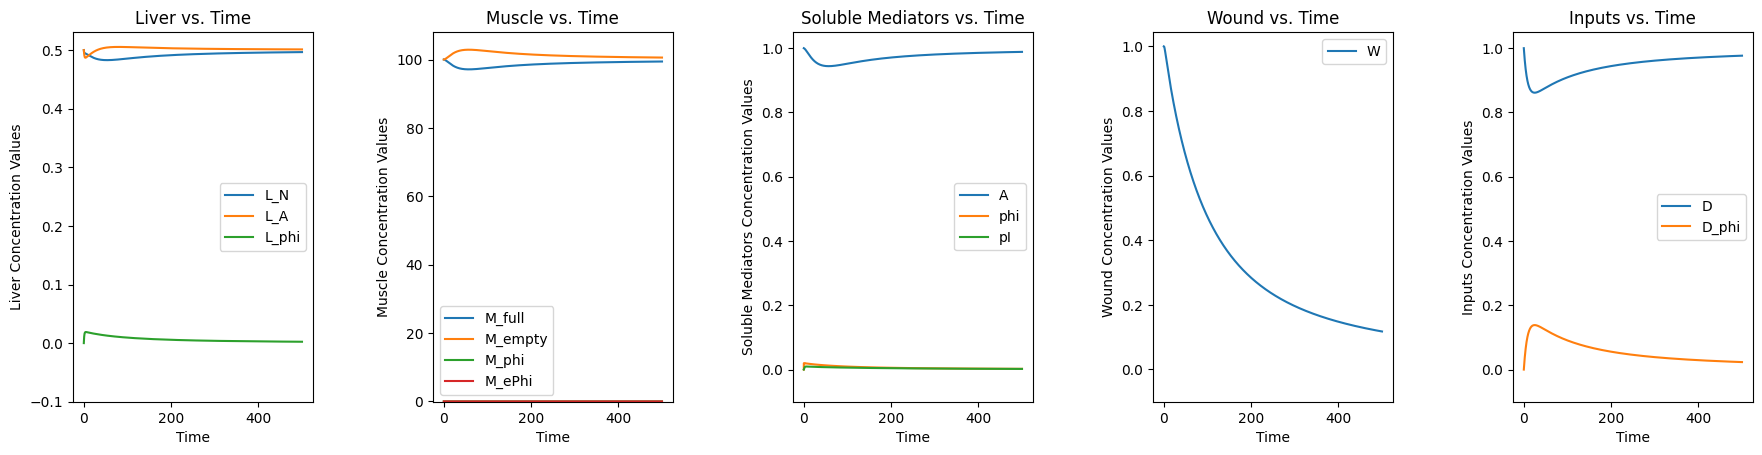

-0.08695652173913043
Final value of W: 0.11747051004869505


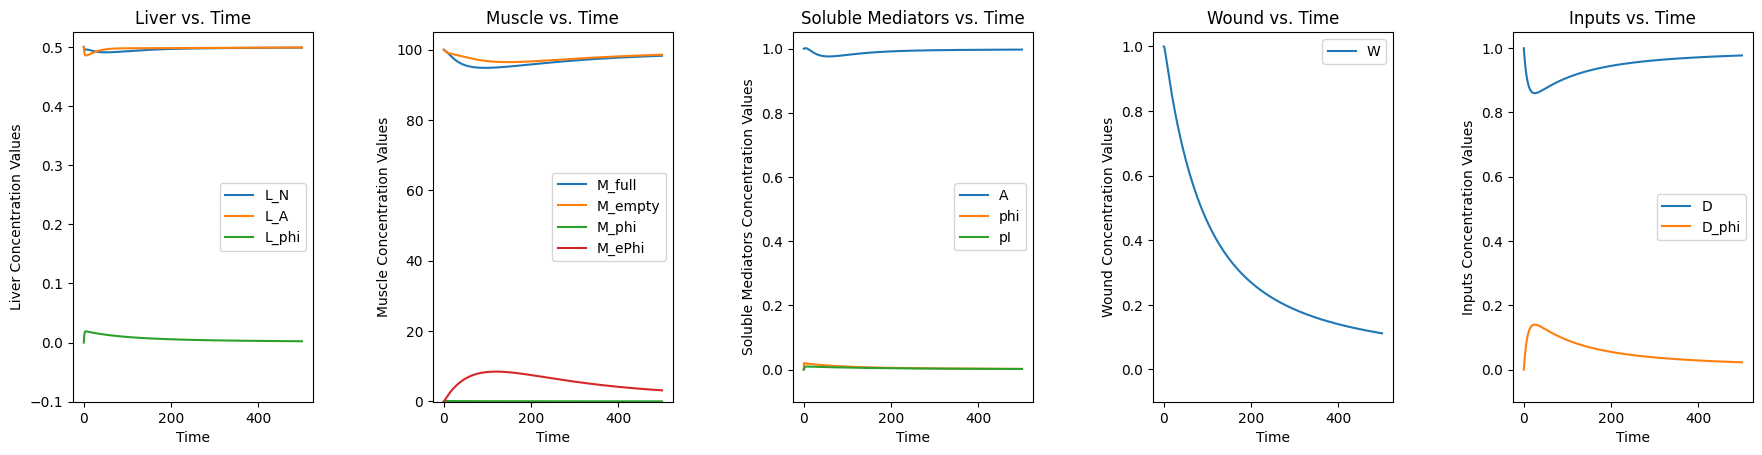

-0.04868867494044182
Final value of W: 0.11184022370255892


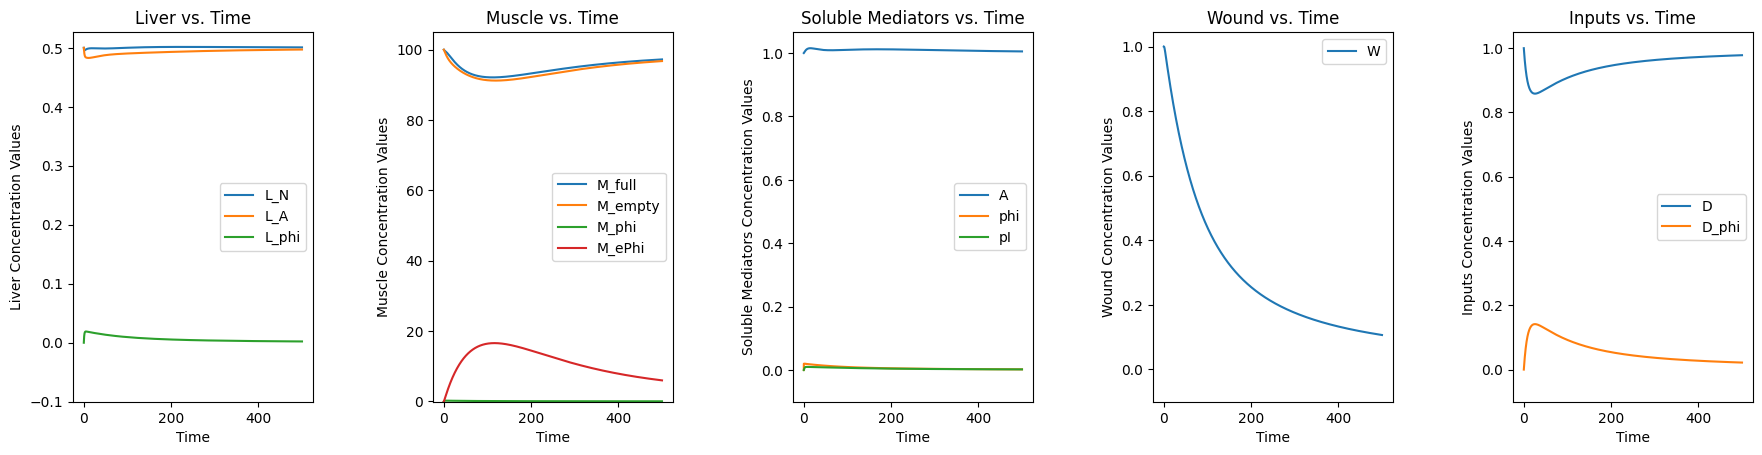

0.008404819306014272
Final value of W: 0.10660803726490355


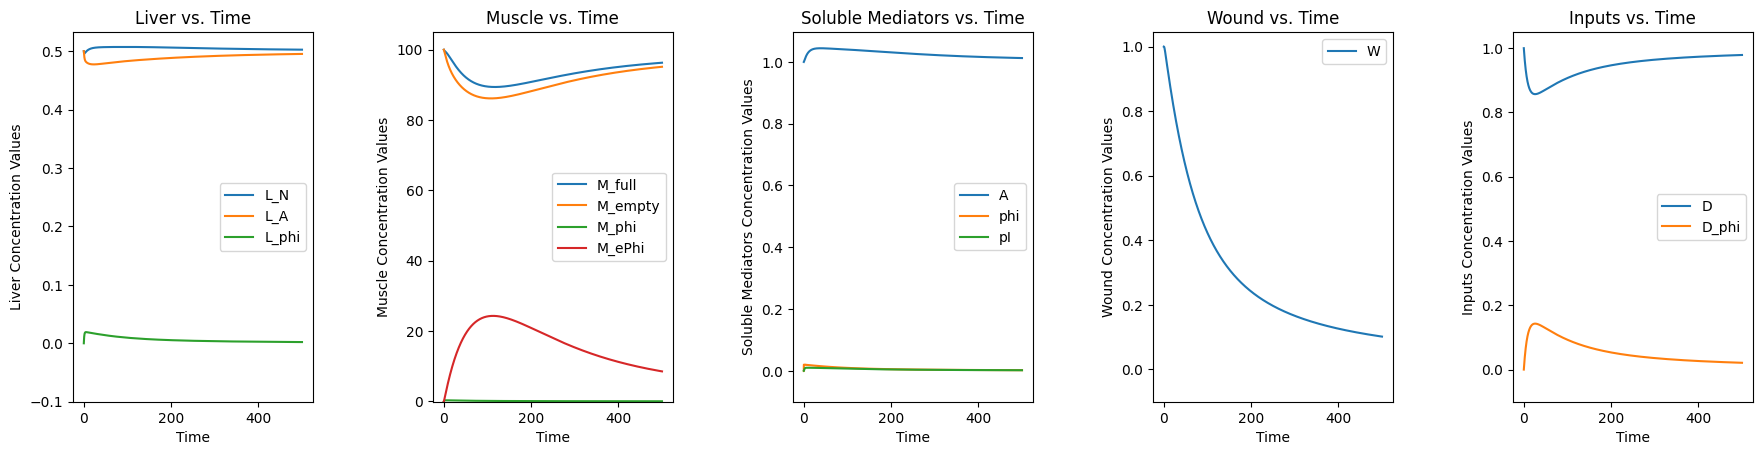

0.06345800662051858
Final value of W: 0.10174902195839354


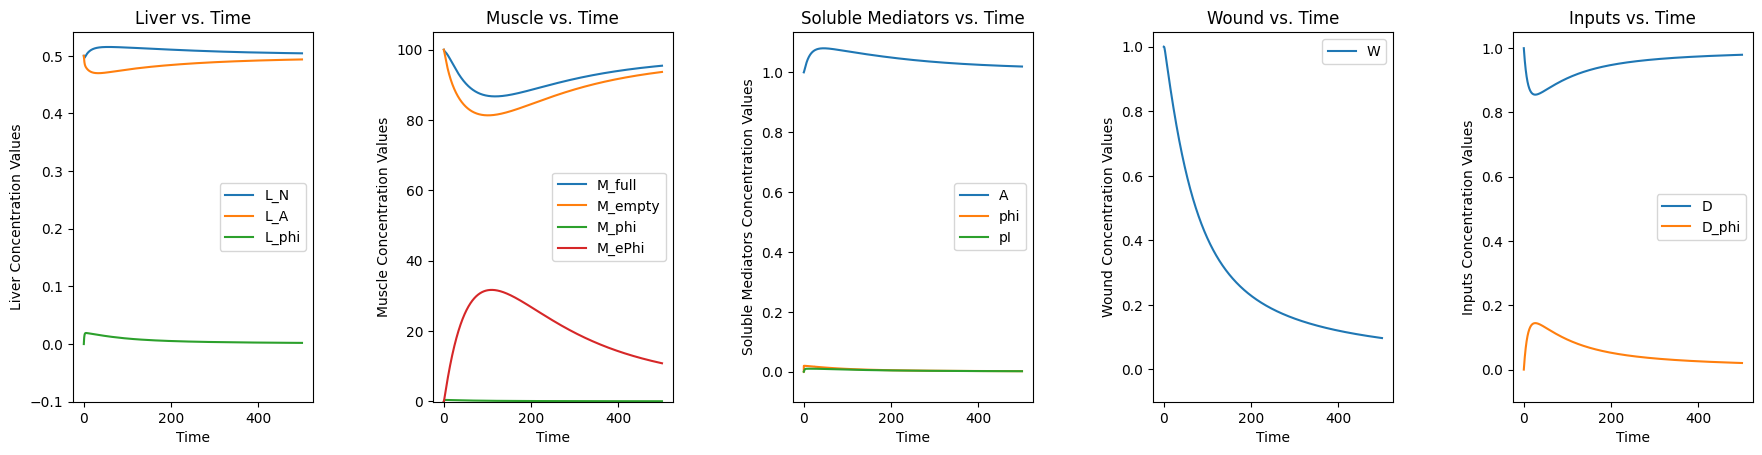

0.1157942468631901
Final value of W: 0.09723829685807858


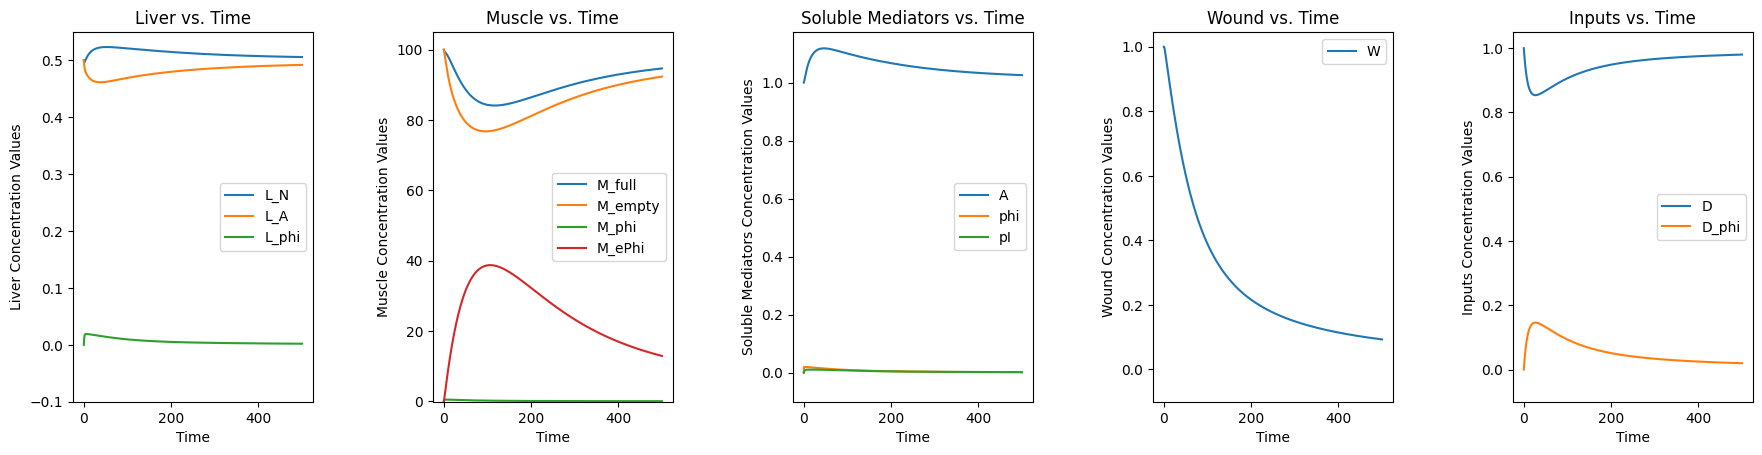

0.16534901770009097
Final value of W: 0.09305144721851377


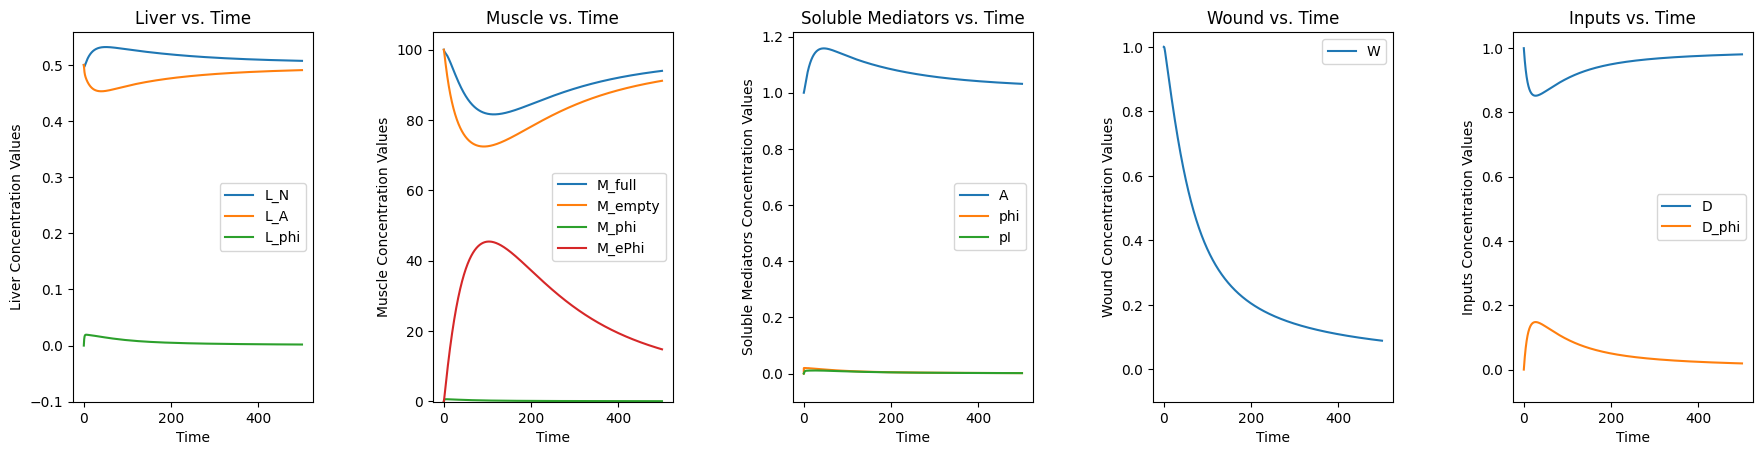

0.2121682000506175
Final value of W: 0.08916484609473825


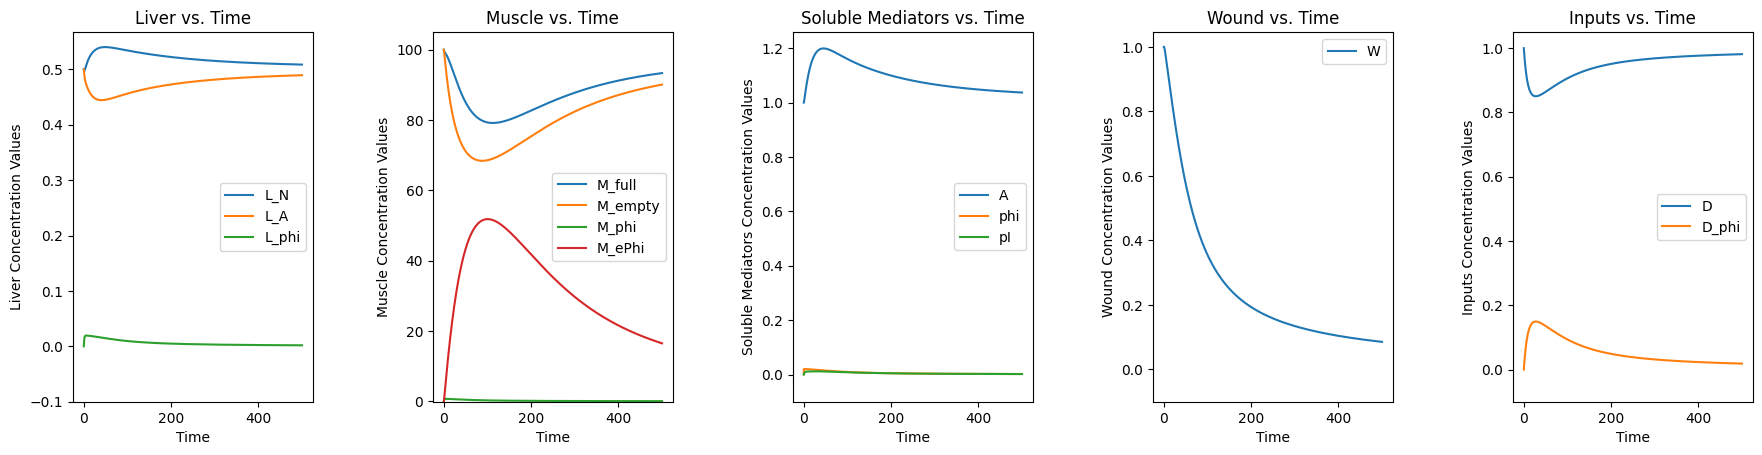

0.25633158766874614
Final value of W: 0.08555588900449738


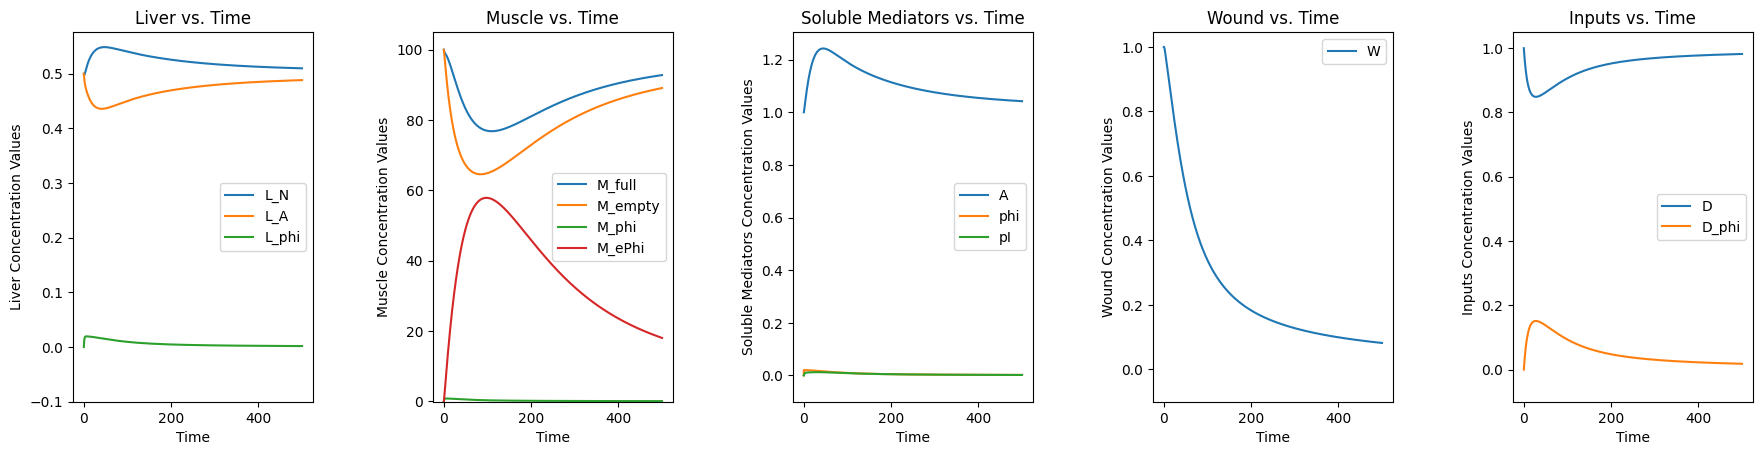

0.2979346618734595
Final value of W: 0.08220315342426203


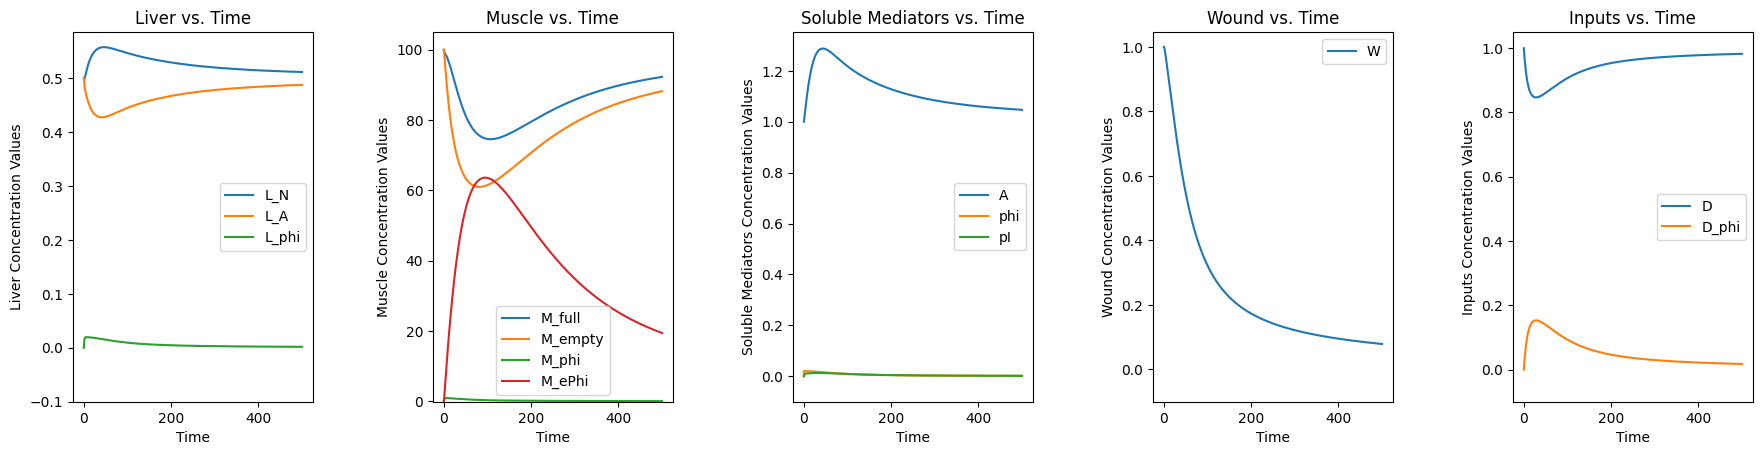

0.3370803687204495
Final value of W: 0.07908649556428796


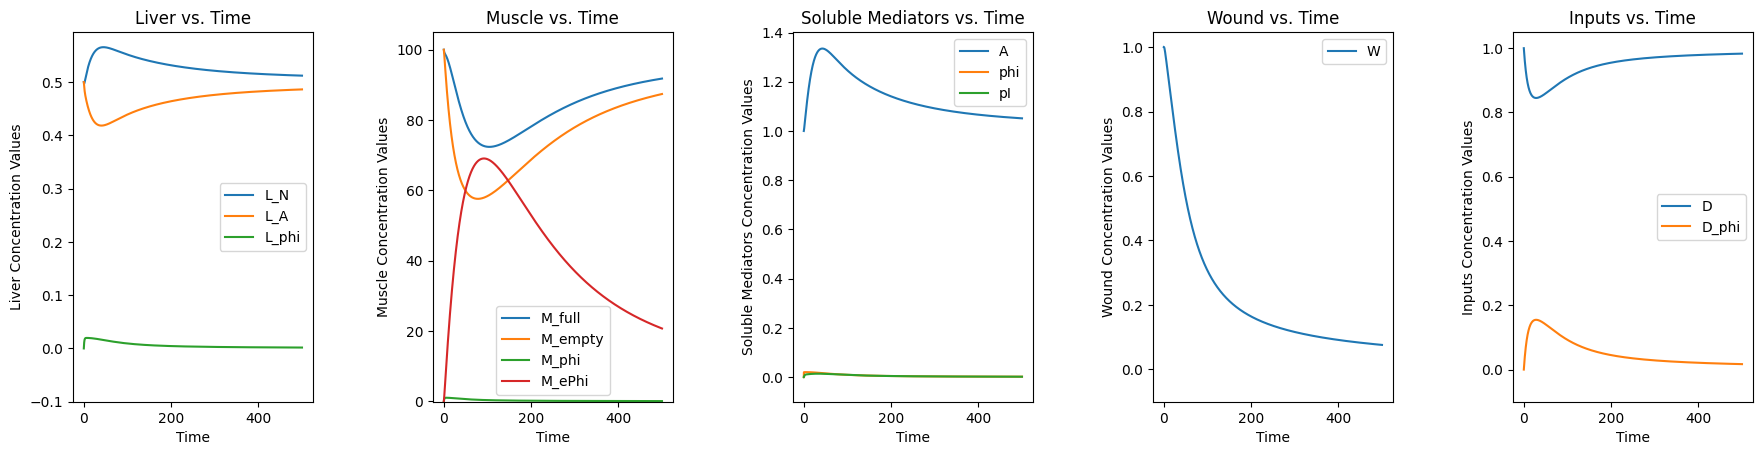

0.37387590201989973
Final value of W: 0.0761870965209156


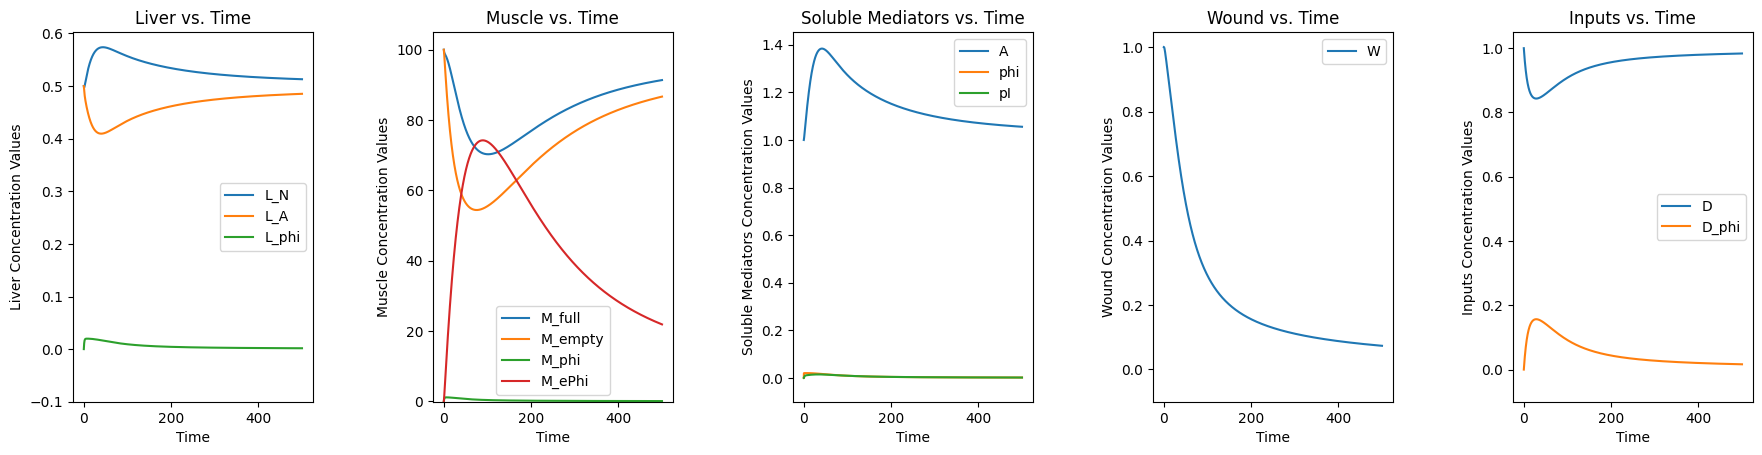

0.40843145317064505
Final value of W: 0.0734874689014808


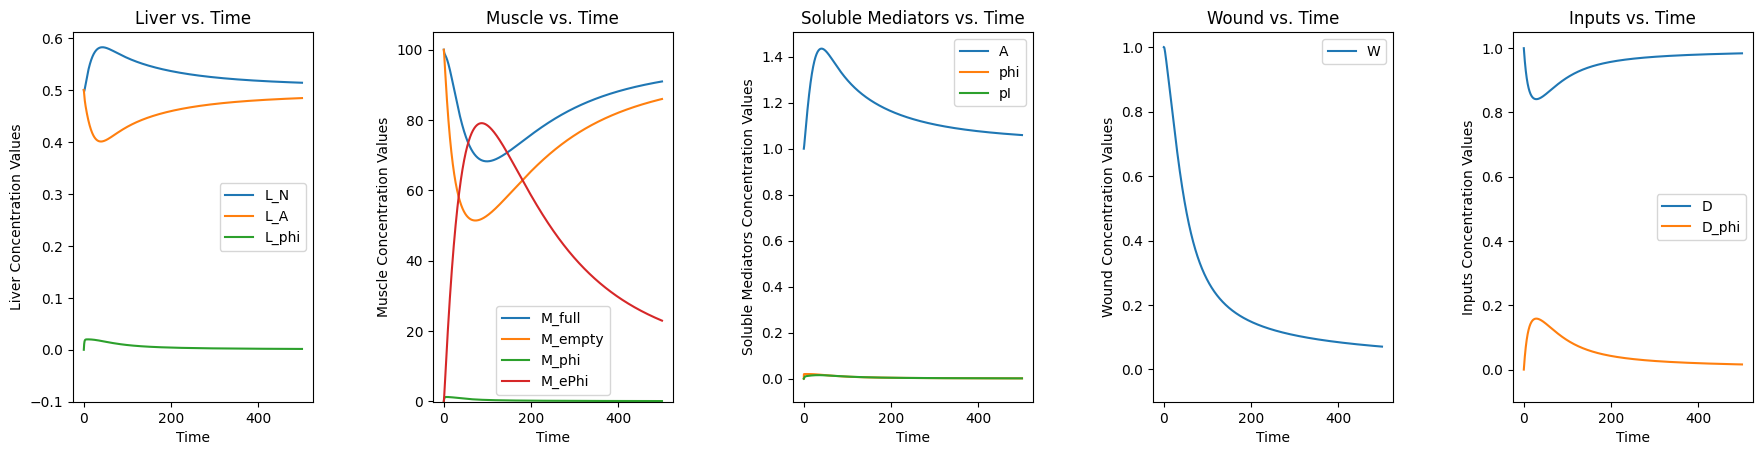

0.4408576949178983
Final value of W: 0.07097143367137024


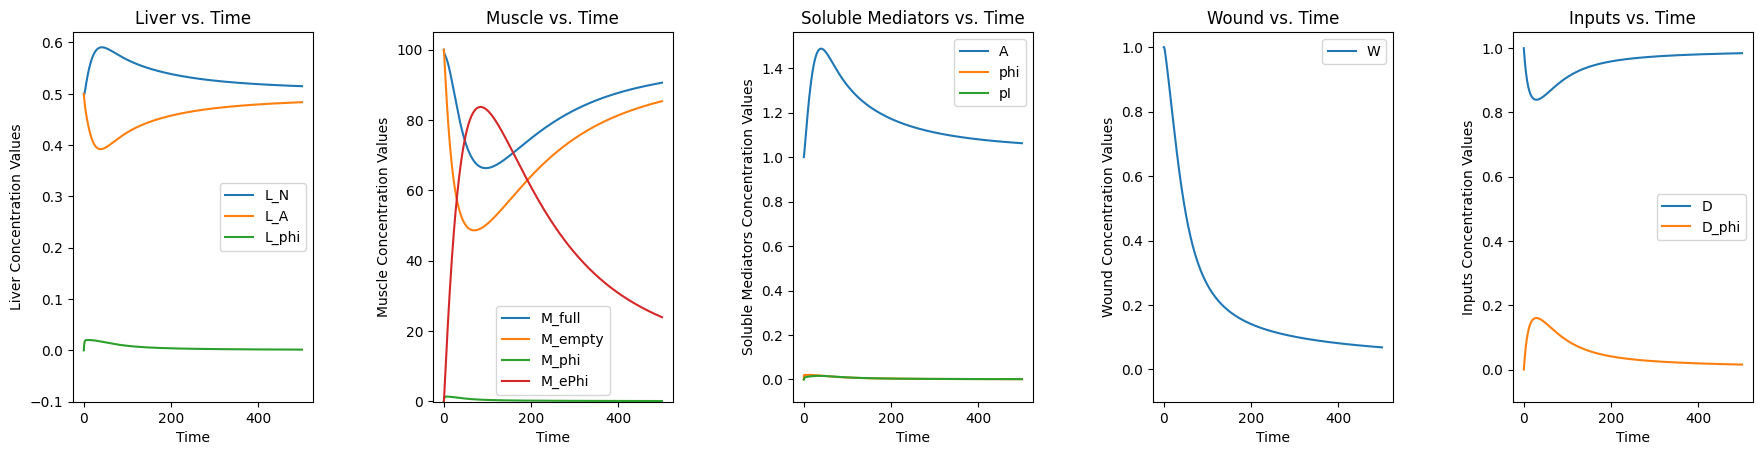

0.4712657027248475
Final value of W: 0.06862407548030211


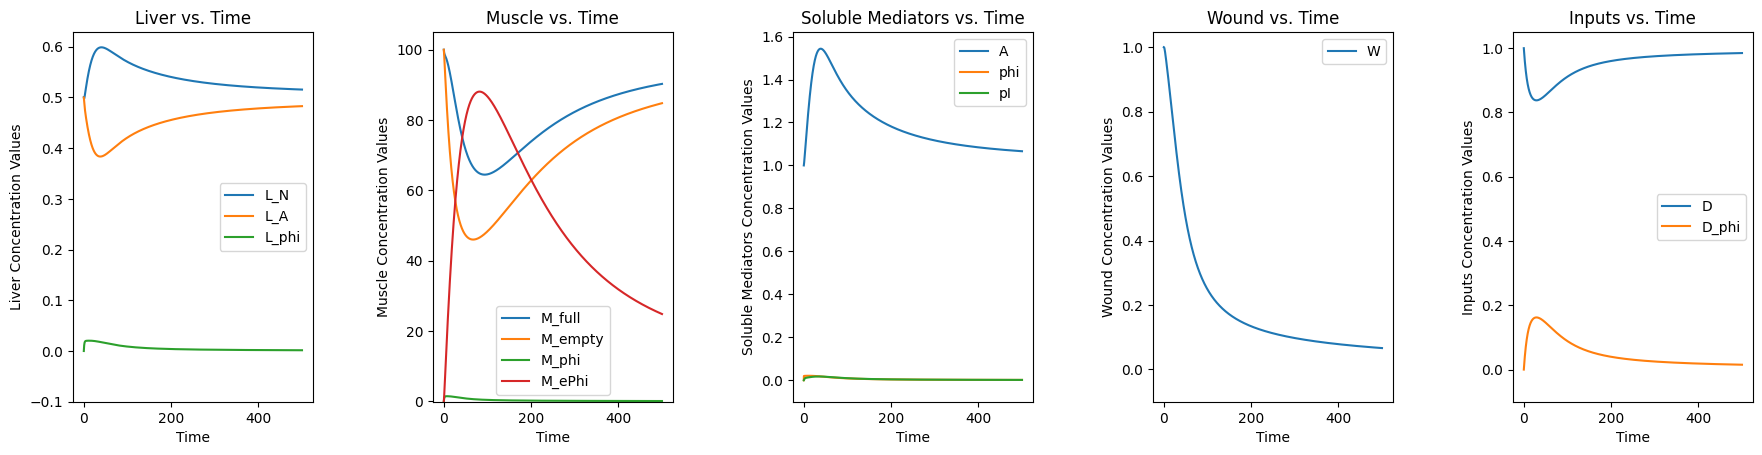

0.49976444346989607
Final value of W: 0.06643168325460827


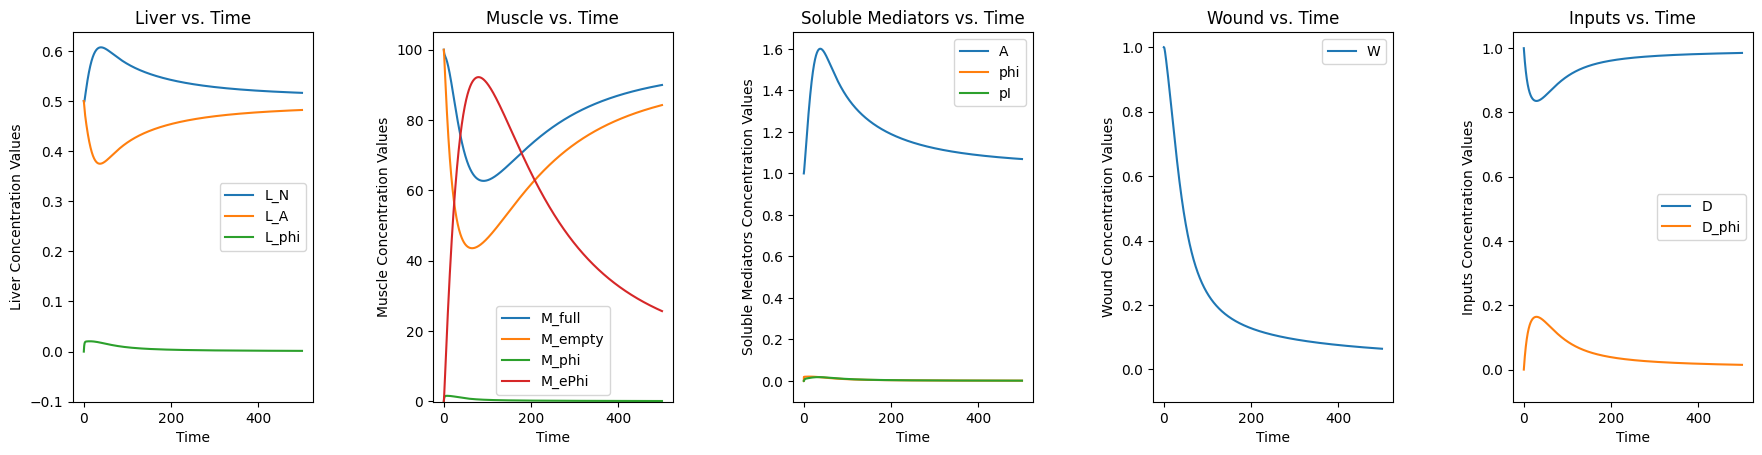

0.5264623499186614
Final value of W: 0.06438168147712649


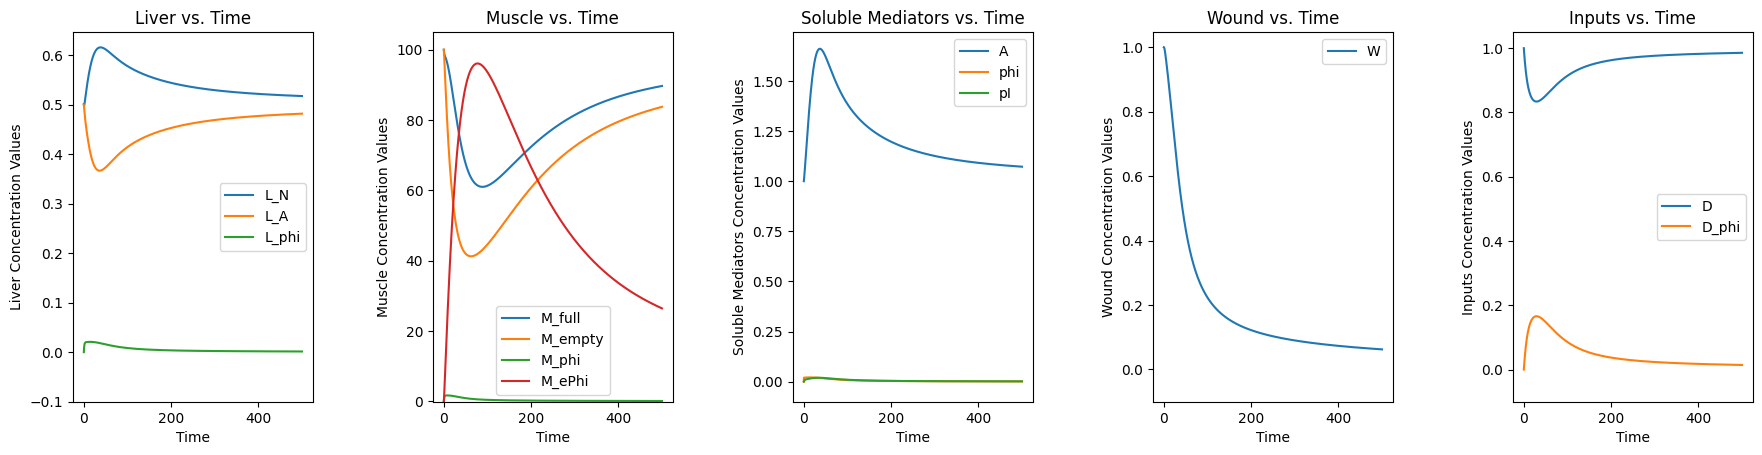

0.5514639254372573
Final value of W: 0.06246255637267194


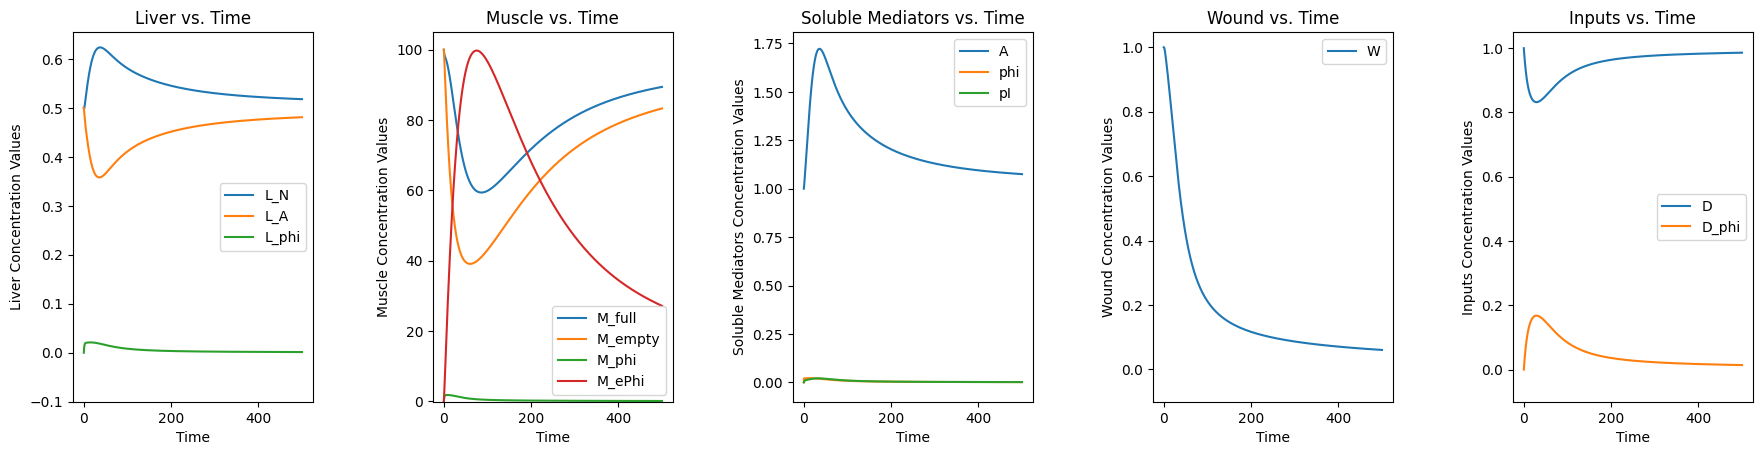

0.5748721255484475
Final value of W: 0.06066378018968686


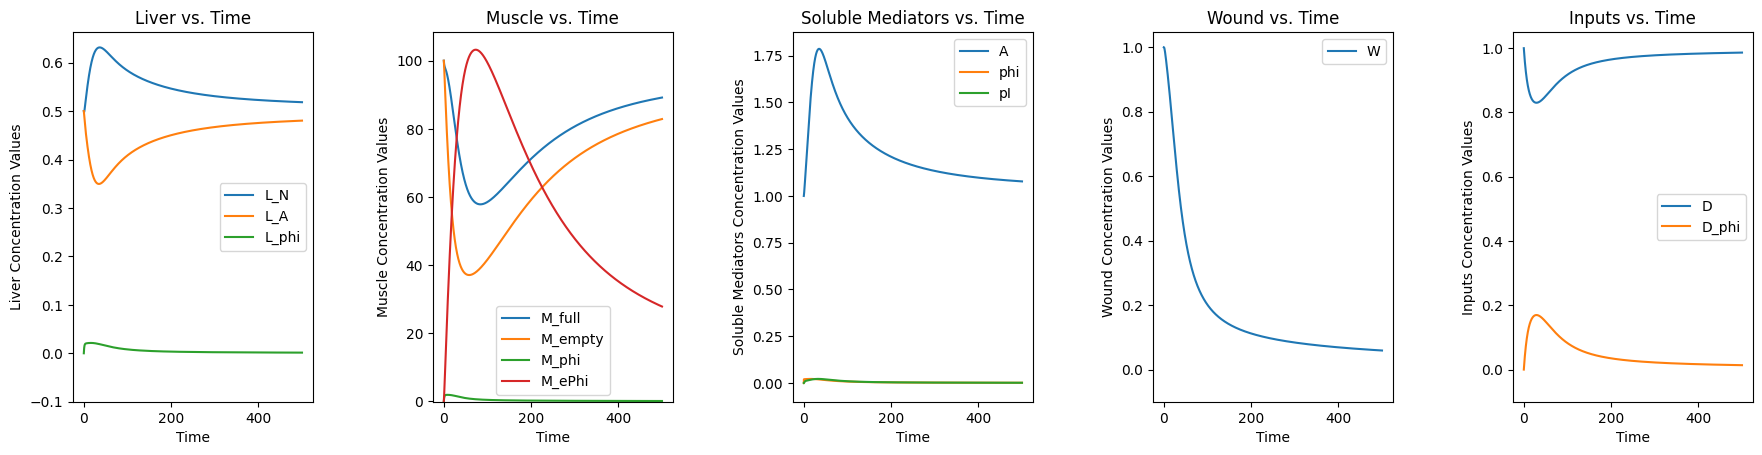

0.5967851171034811
Final value of W: 0.0589757359226348


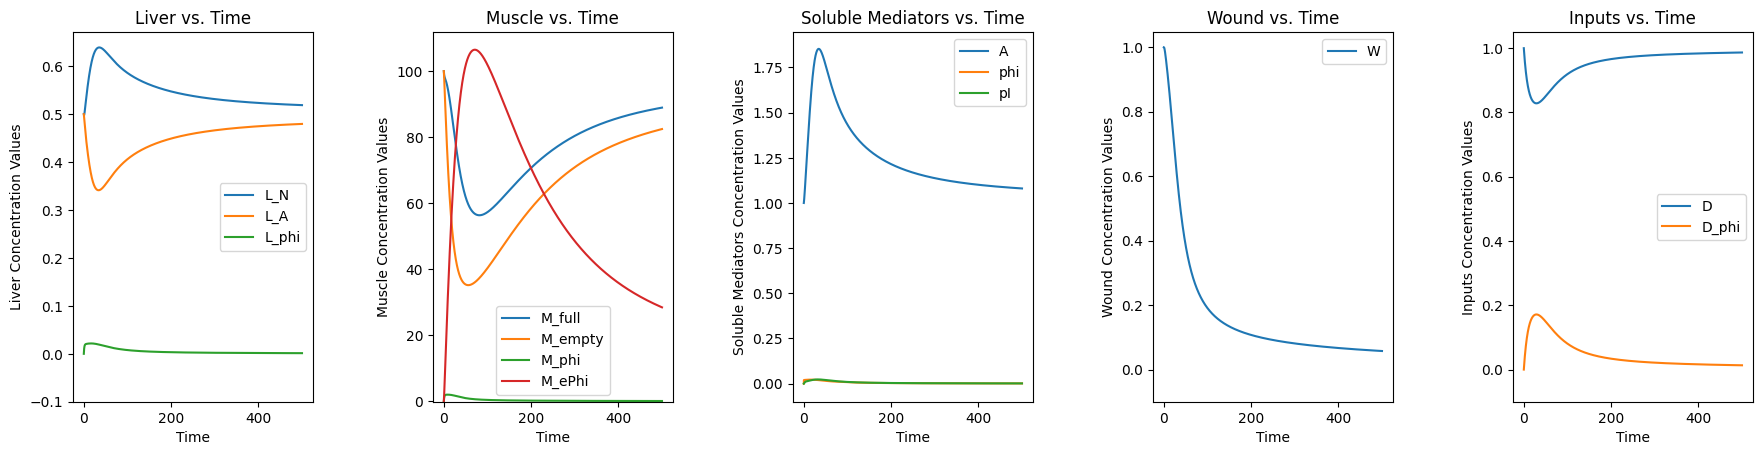

0.6172976661979704
Final value of W: 0.05738964413508947


In [ ]:
initWound = 1

diet = 1

woundValsVsTime = []

rxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_A', 'L_phi'], "Muscle" : ['M_full', 'M_empty', 'M_phi', 'M_ePhi'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

rxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0])

lowSimulationOutputs = []

rxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
rxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
rxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
rxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationParameters["low"], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
rxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
rxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
rxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
#rxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
#rxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 7: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
rxnFlask.addReaction("Reaction 22: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 8: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
rxnFlask.addReaction("Reaction 23: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    R = (1 / (numPointsToTest - 1)) * k

    #rxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = R)
    #rxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = 1 - R)


    #This allows S_empty to continue acting as an inflammation sink without changing state
    #rxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = R)
    #rxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = 1 - R)


    #This allows M_full to continue acting as an inflammation sink while not changing state
    rxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = R)
    rxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 1 - R)


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    rxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = R)
    rxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 1 - R)

    reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    rxnFlask.runSystem(500)
    
    
    rxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = rxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - rxnFlask.latestSimulationOutput["y"][7] - rxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {rxnFlask.getFinalValueOfSpecies('W')}")

    rxnFlask.resetInitialCondition()

    lowSimulationOutputs.append(rxnFlask.latestSimulationOutput)

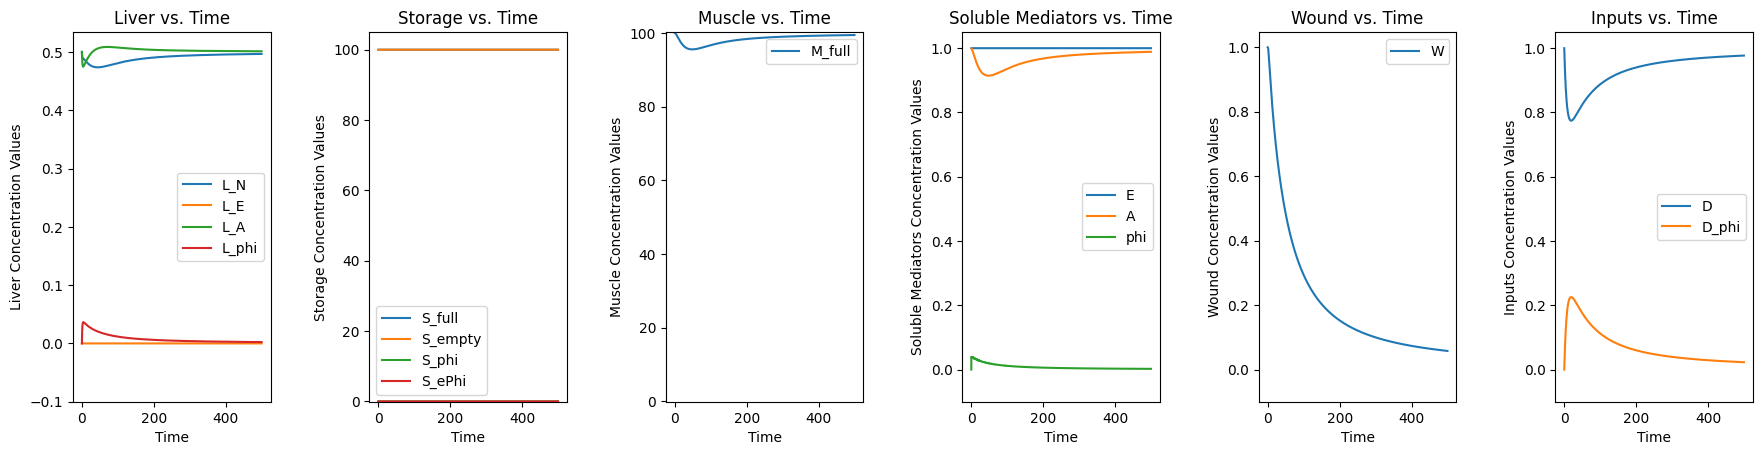

-1.1254059564221166
Final value of W: 0.05766038994299212


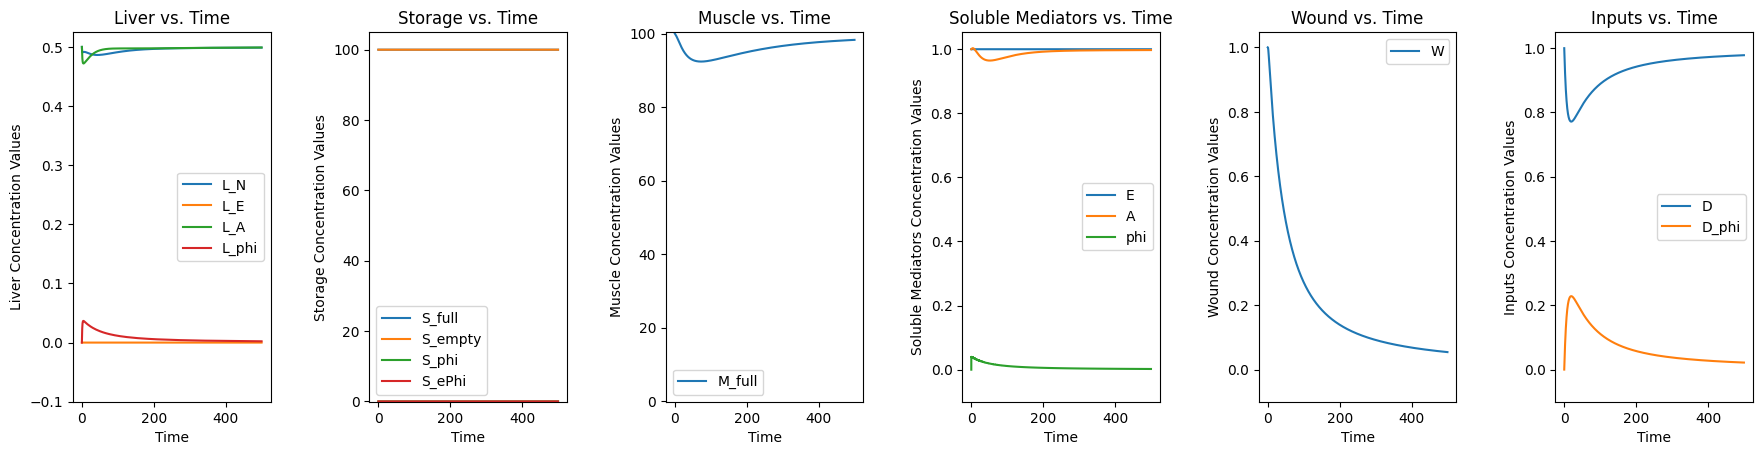

-1.0910528287548453
Final value of W: 0.05401855123713057


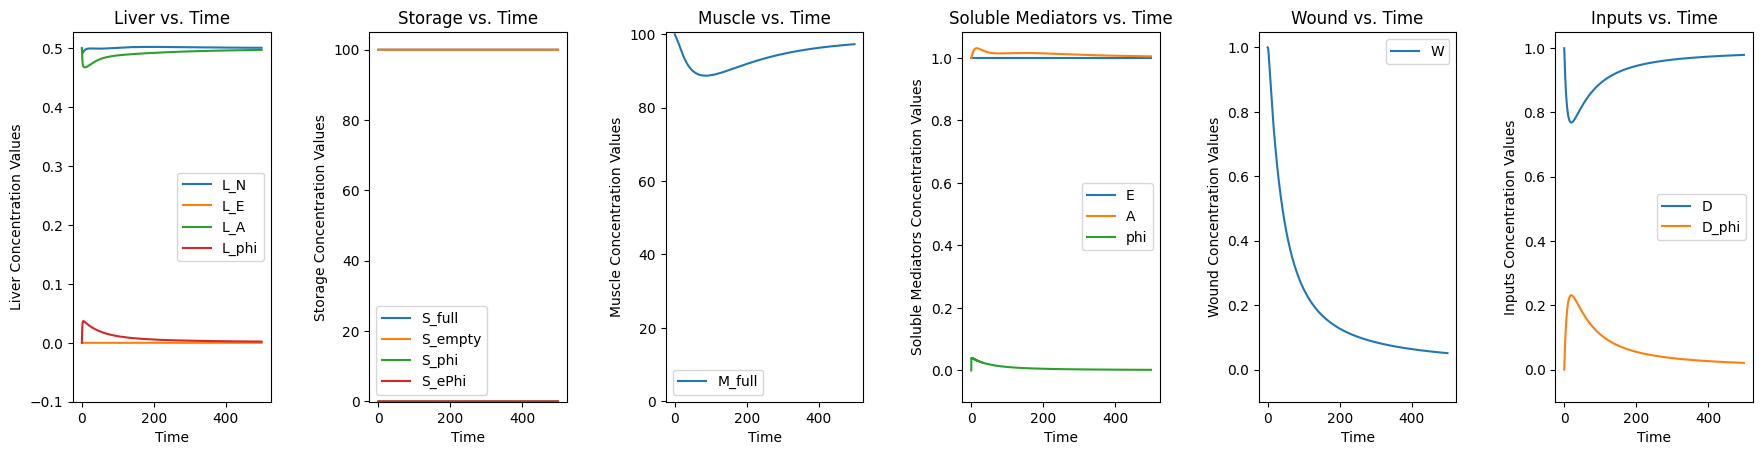

-1.0511233247720355
Final value of W: 0.050781790554437795


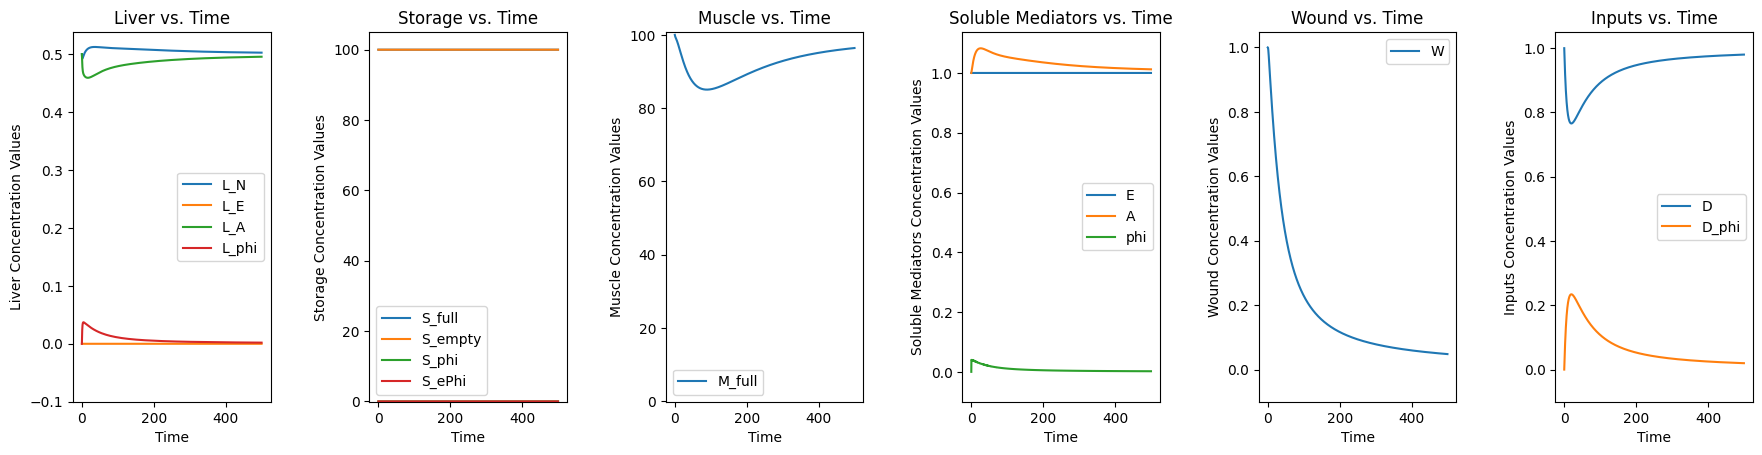

-1.0115099151535305
Final value of W: 0.04789847567554018


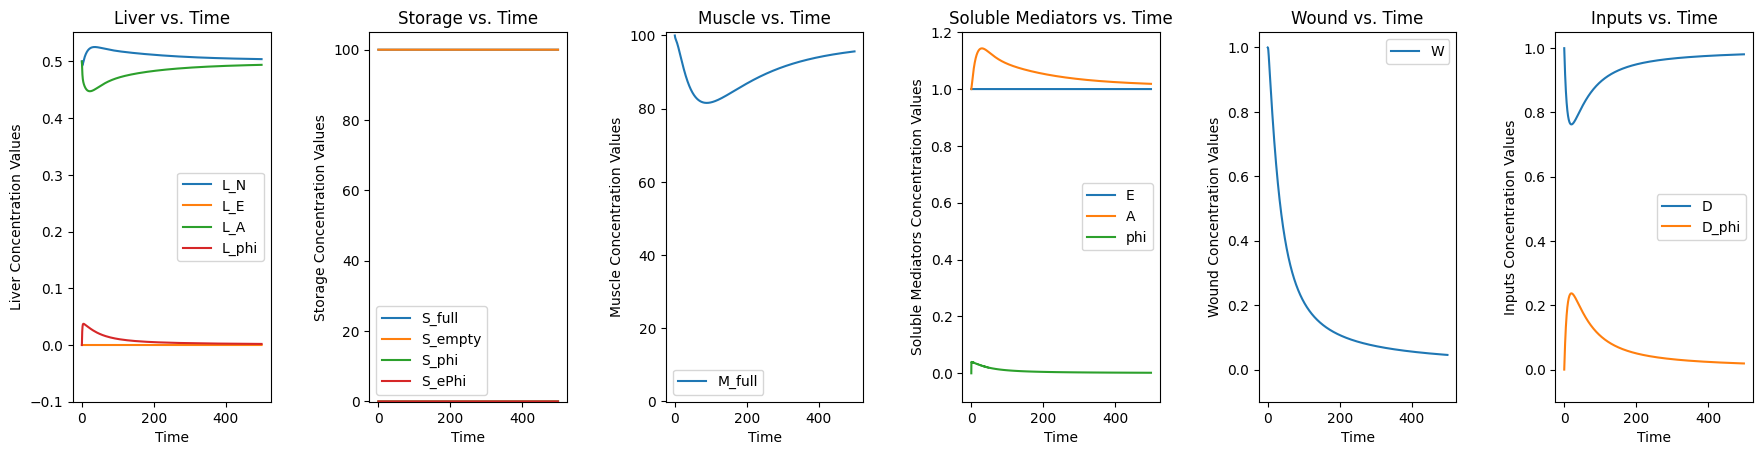

-0.9736413287888356
Final value of W: 0.04532338768246854


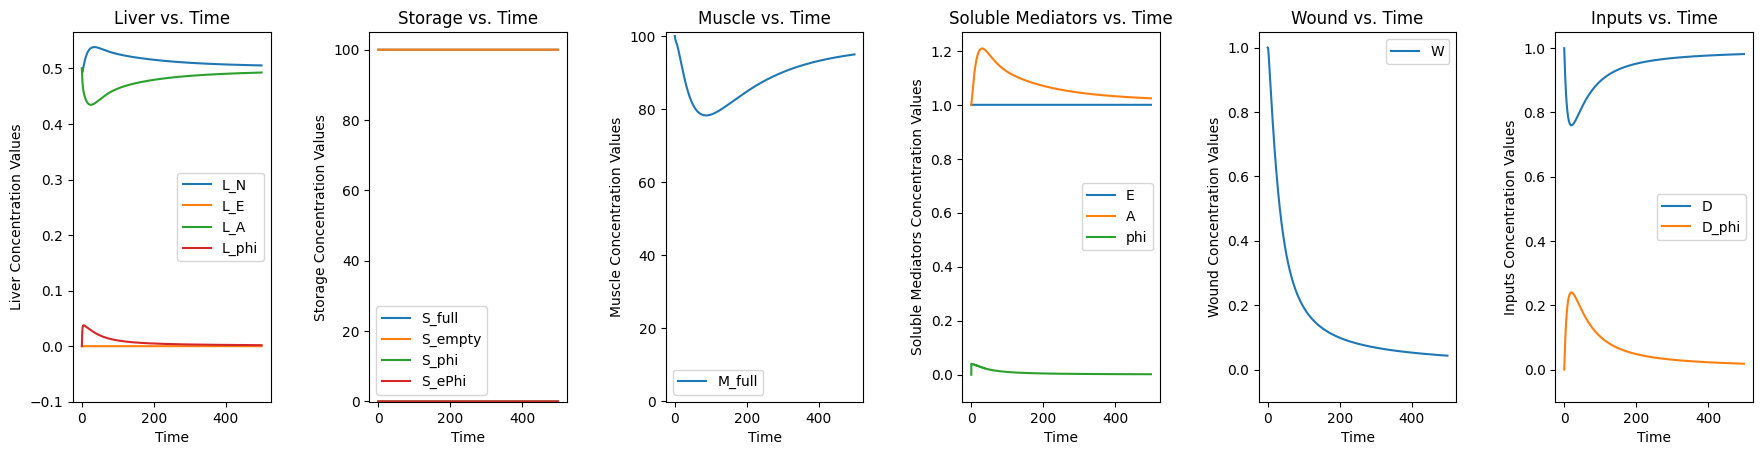

-0.9378351686042901
Final value of W: 0.043017163726608354


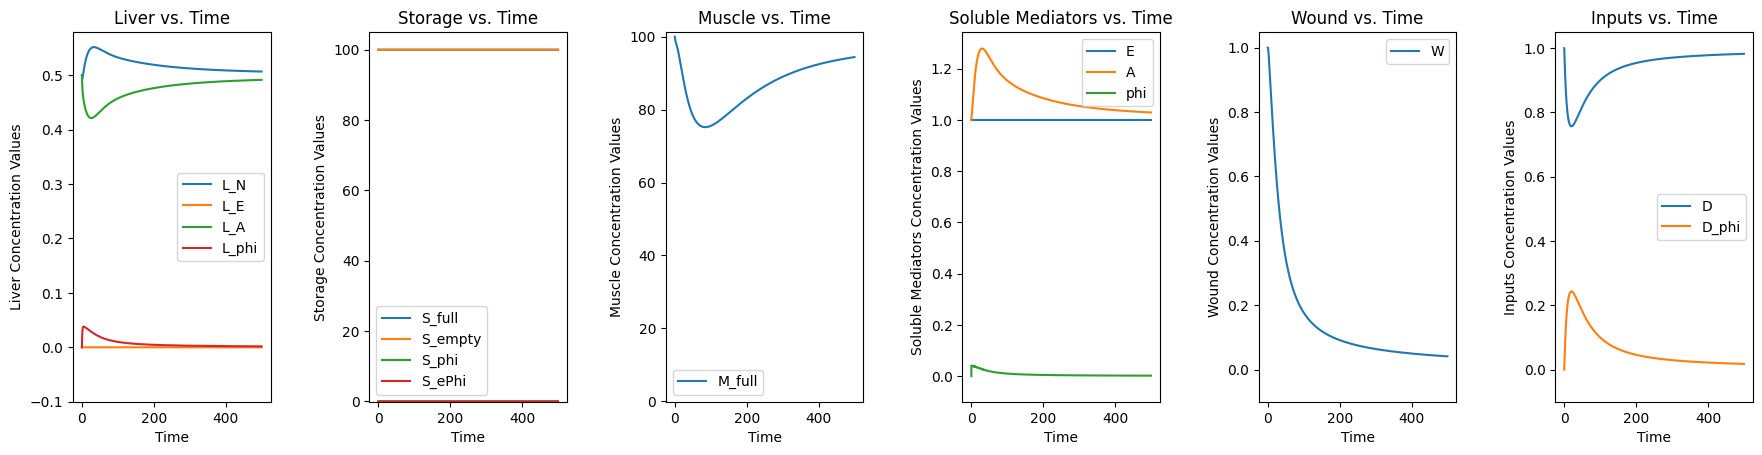

-0.9041541705203294
Final value of W: 0.040945680208026254


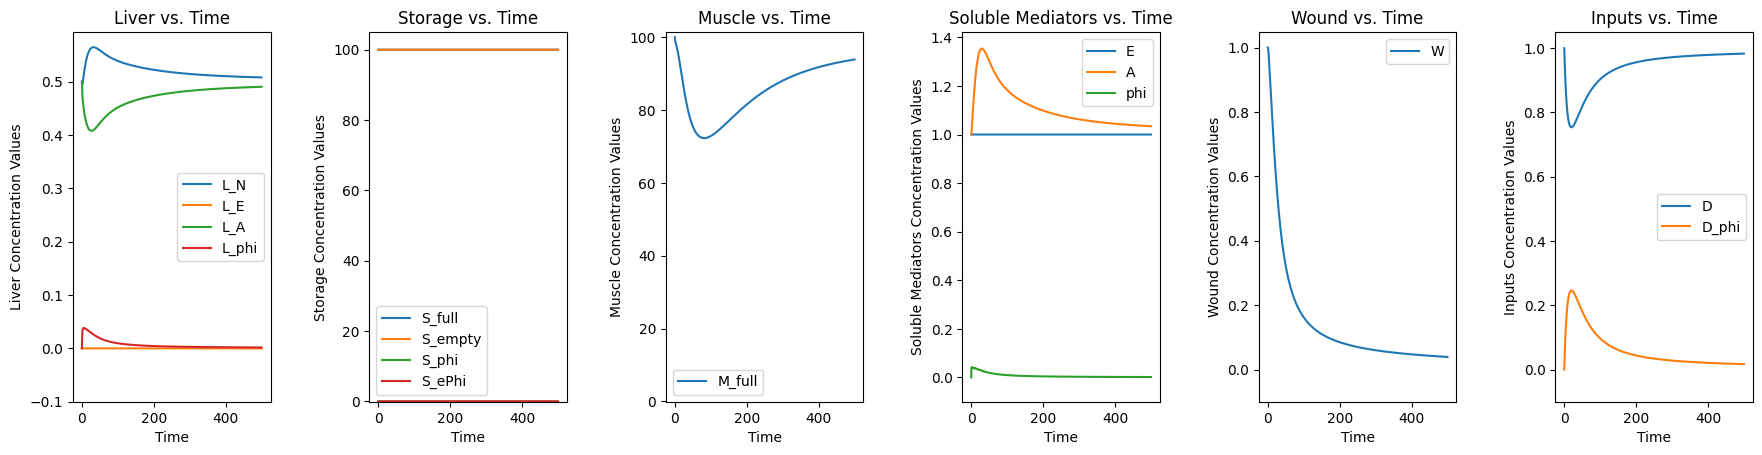

-0.872575897708375
Final value of W: 0.03907943235668123


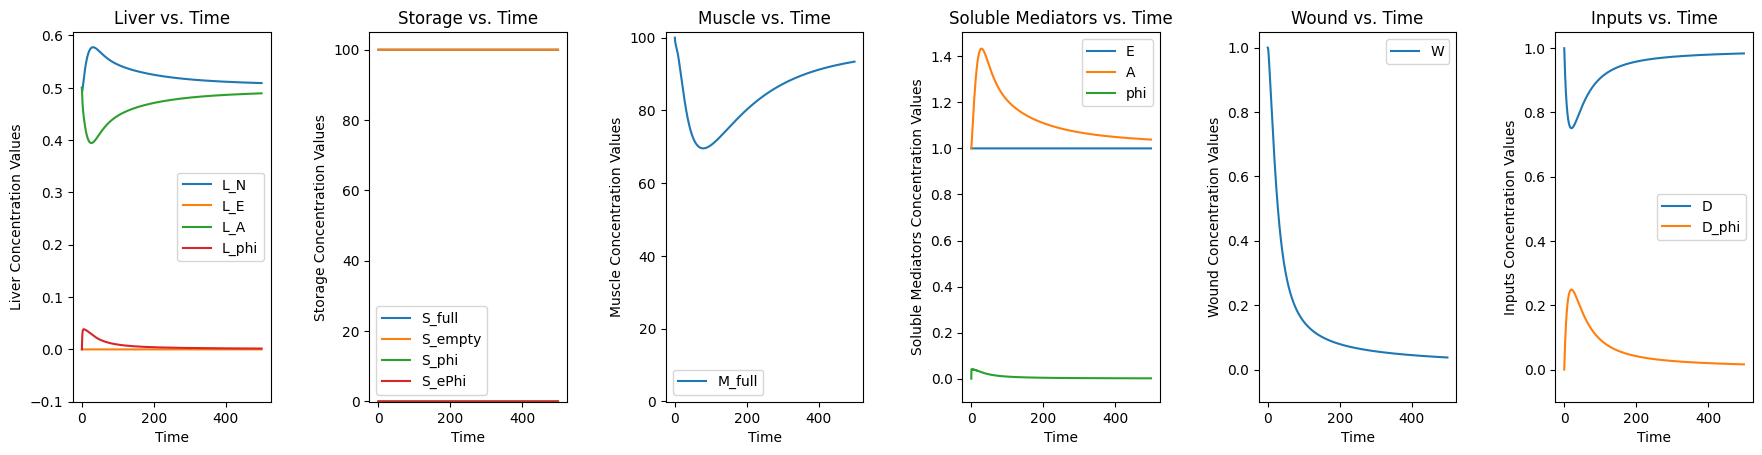

-0.843040186635297
Final value of W: 0.03739294433714897


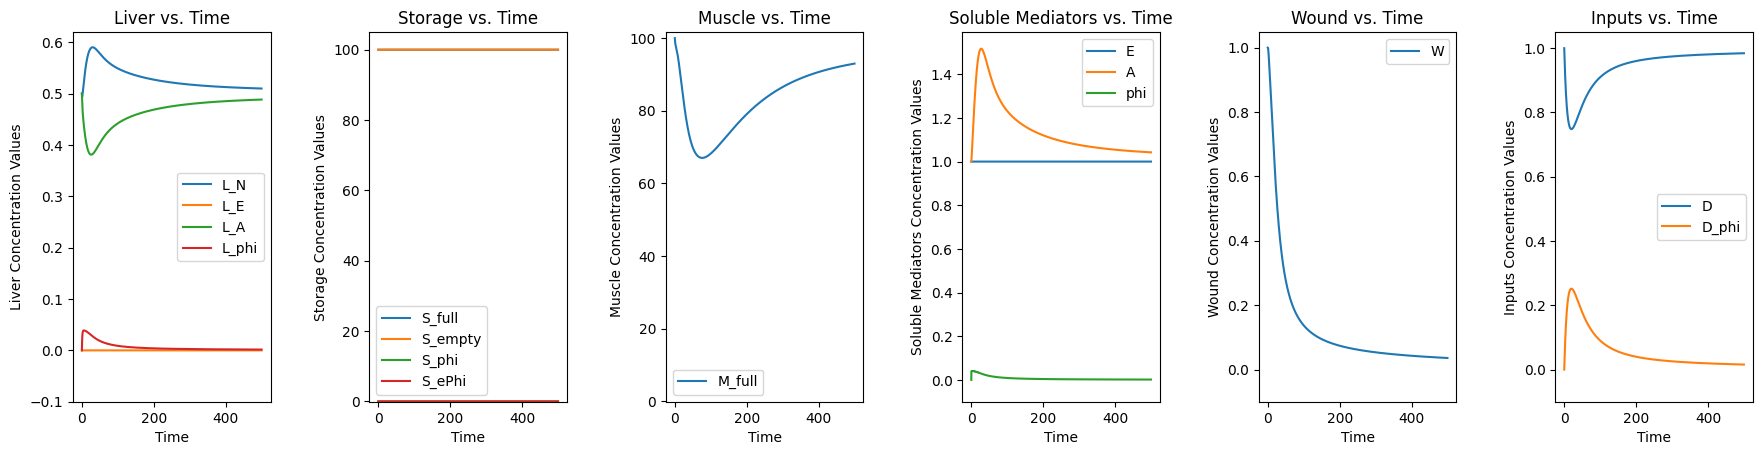

-0.8154665837184527
Final value of W: 0.0358642284085348


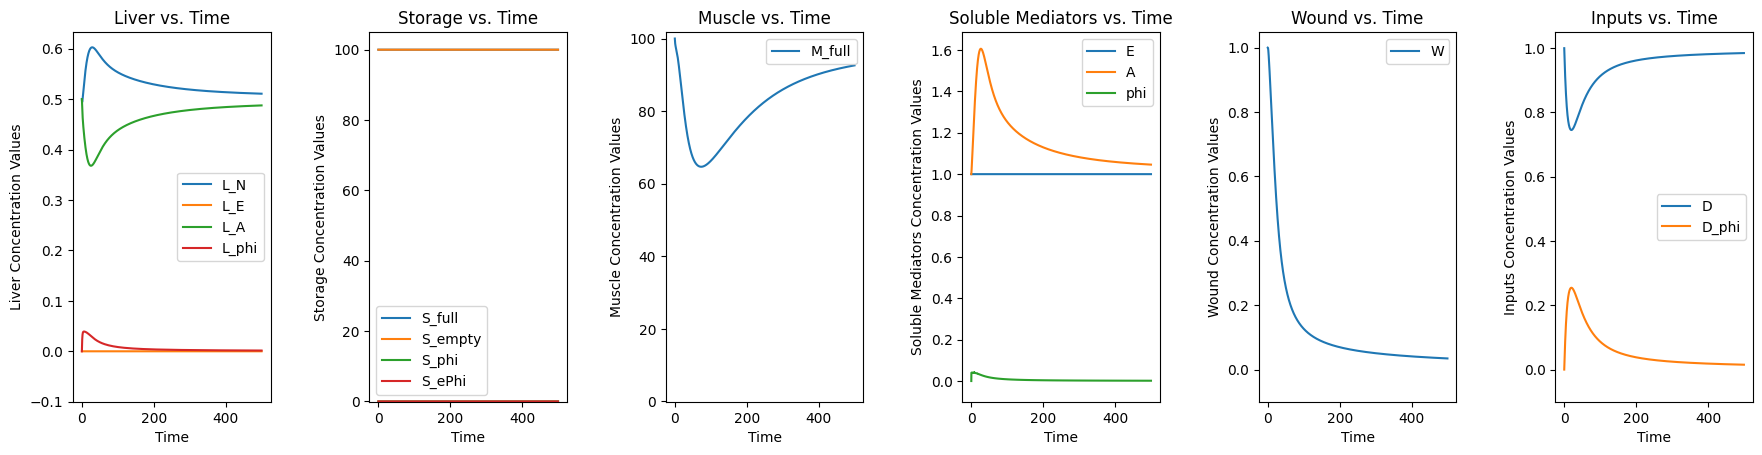

-0.7897627485487378
Final value of W: 0.03447430117528406


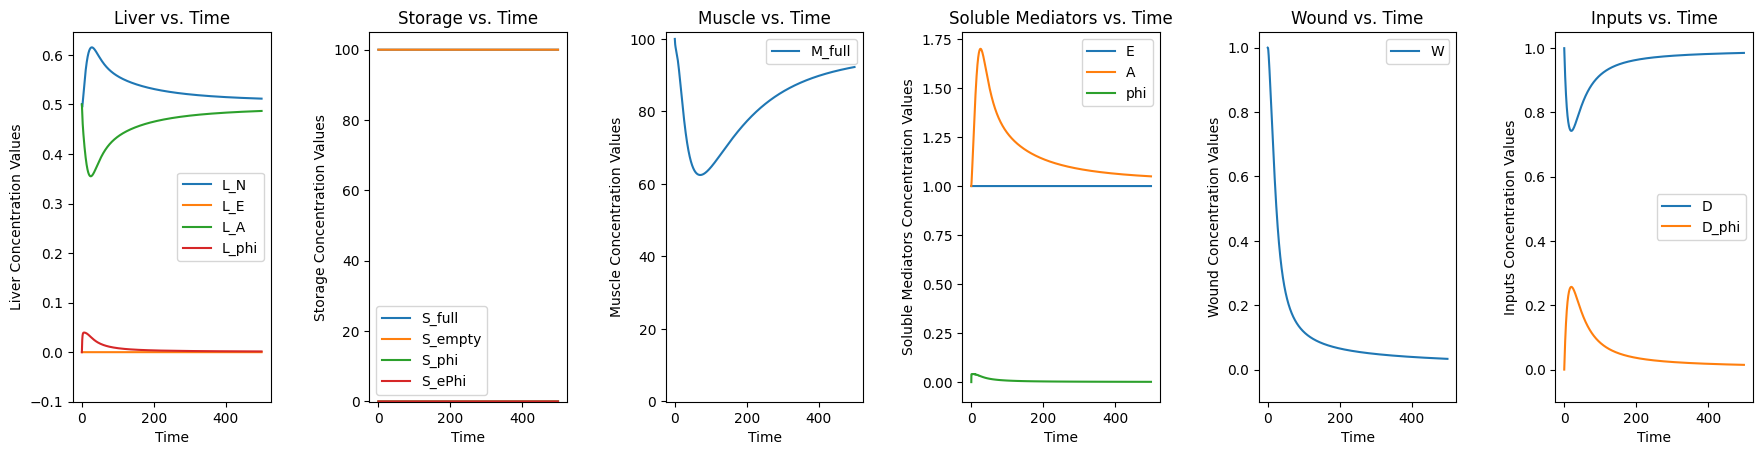

-0.7658300894969182
Final value of W: 0.03320675830792306


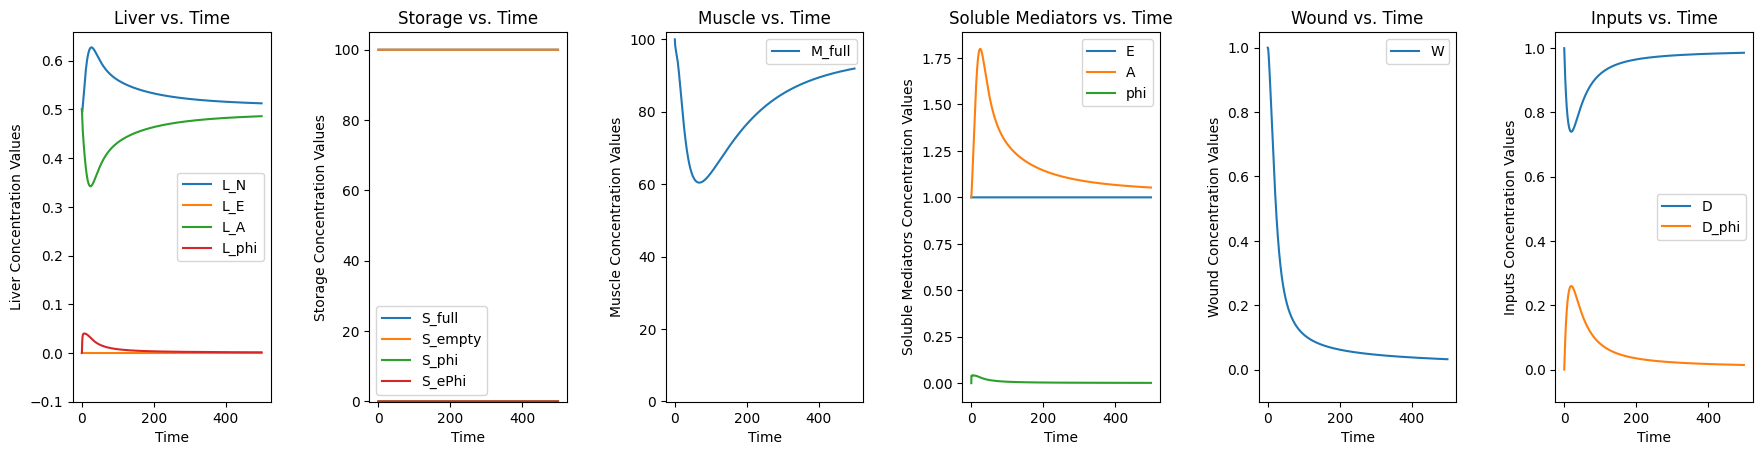

-0.7435664464841968
Final value of W: 0.032047405186100775


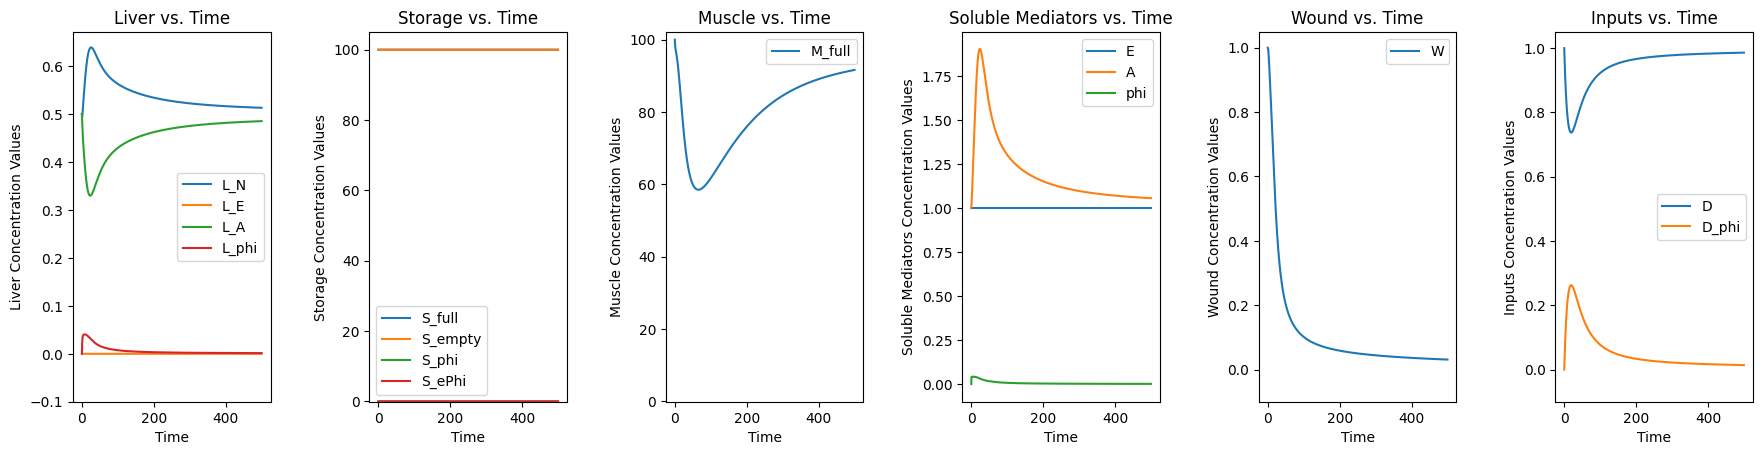

-0.7228688169656001
Final value of W: 0.03098393882569588


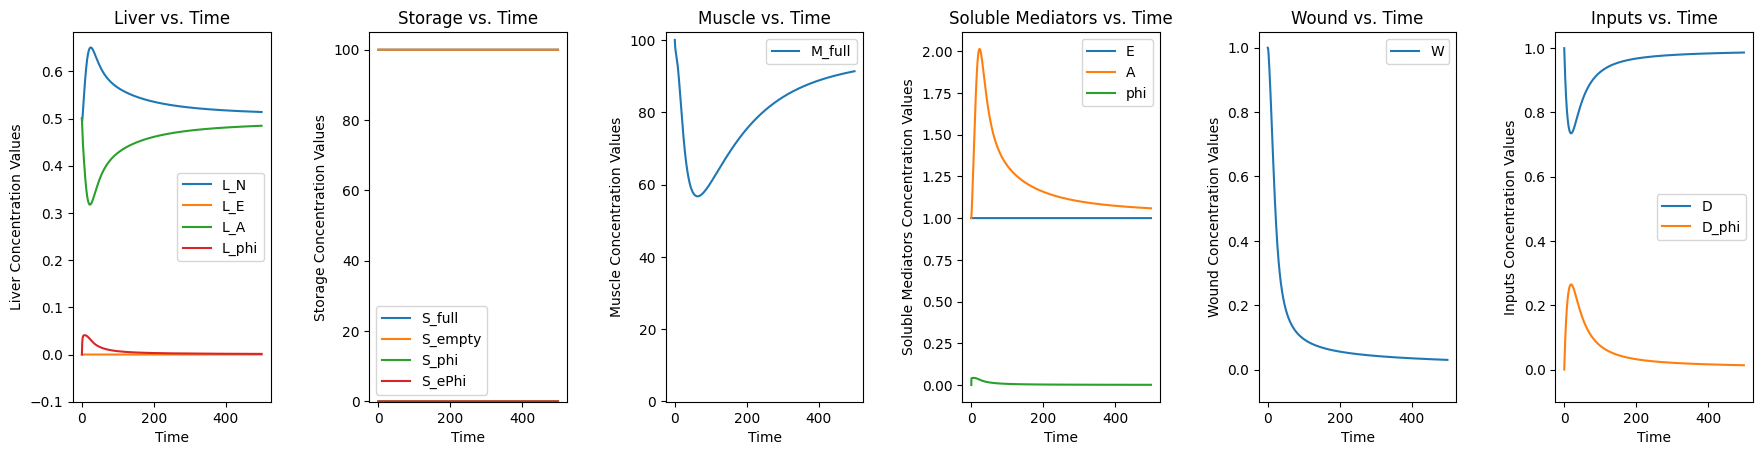

-0.7036354781621632
Final value of W: 0.030005675558979133


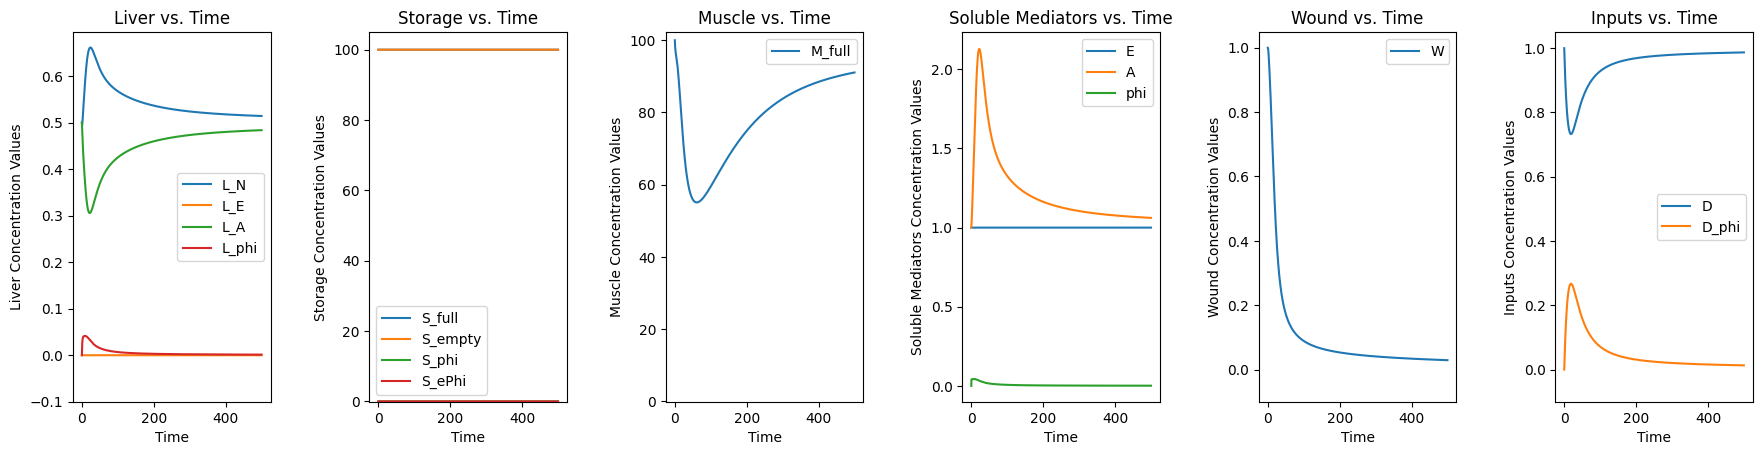

-0.6857670082669092
Final value of W: 0.029103318769140386


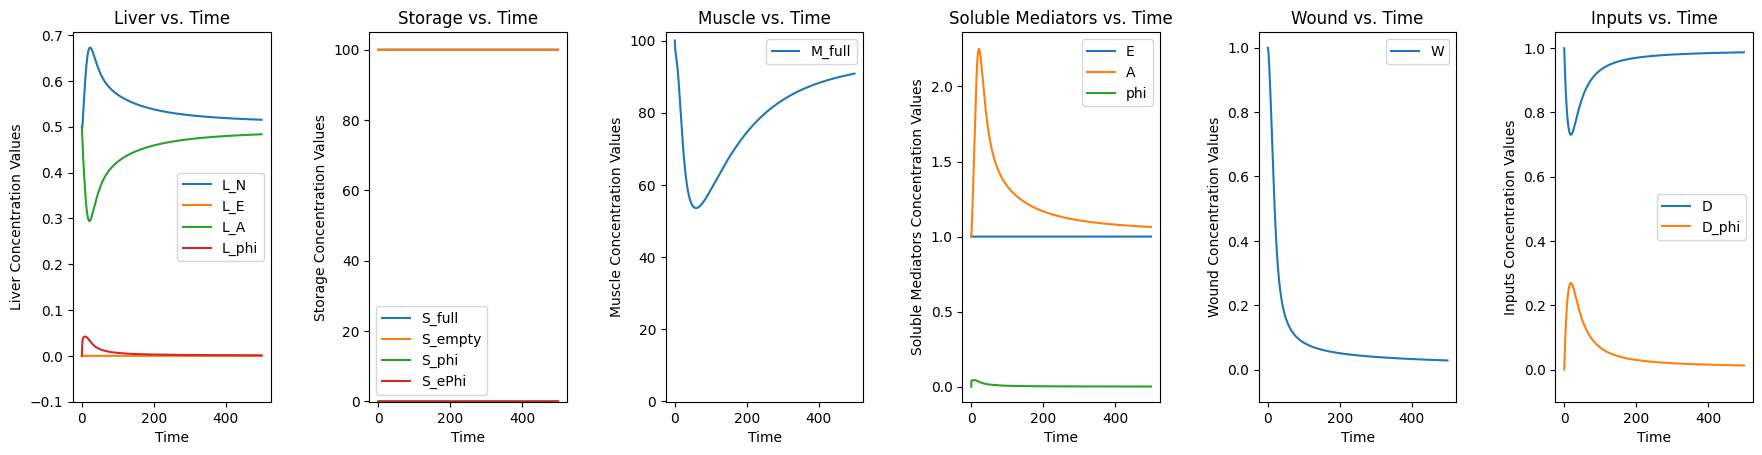

-0.6691680418699926
Final value of W: 0.028268761231588176


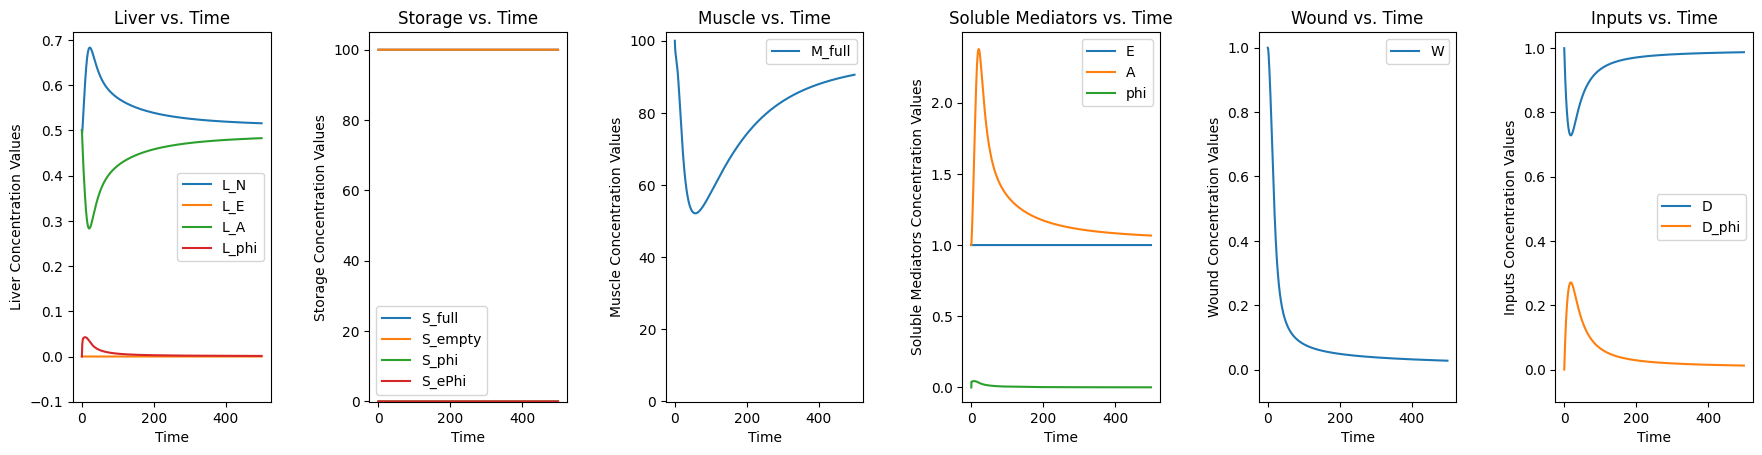

-0.6537470342701157
Final value of W: 0.02749491708236754


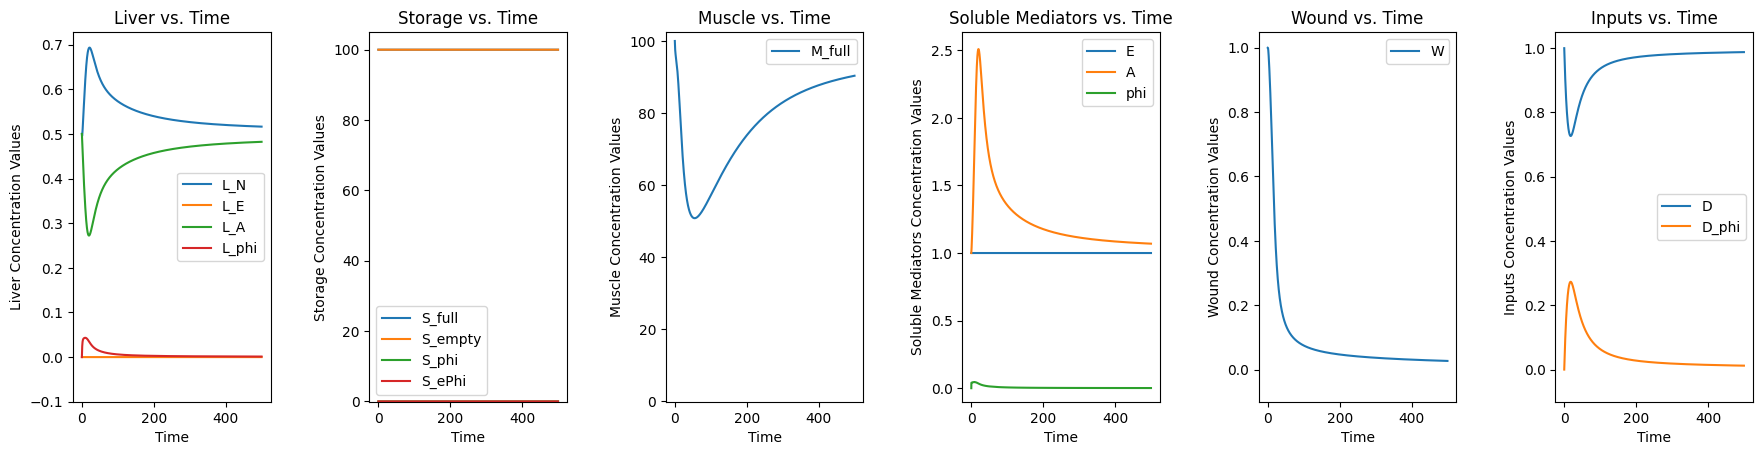

-0.6394175044726571
Final value of W: 0.026775578991472284


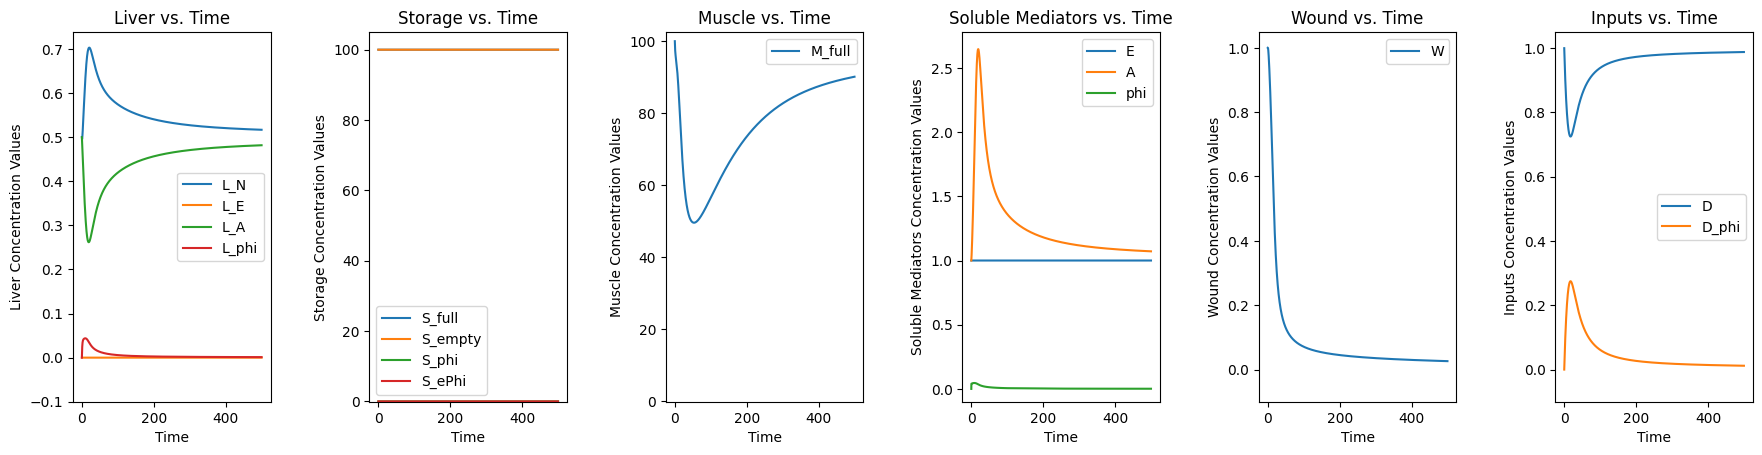

-0.6260982713025656
Final value of W: 0.02610529668748916


In [ ]:
initWound = 1

diet = 1

midwoundValsVsTime = []

midrxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_E', 'L_A', 'L_phi', 'S_full', 'S_empty', 'S_phi', 'S_ePhi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'E', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Storage" : ['S_full', 'S_empty', 'S_phi', 'S_ePhi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['E', 'A', 'phi'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

midrxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

midSimulationOutputs = []

midrxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
midrxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 3: L_A + A -> L_N", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
midrxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
midrxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationParameters["mid"], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
midrxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
midrxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
midrxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
midrxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
midrxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
midrxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
midrxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
midrxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
midrxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
midrxnFlask.addReaction("Reaction 7: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
midrxnFlask.addReaction("Reaction 22: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
midrxnFlask.addReaction("Reaction 8: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
midrxnFlask.addReaction("Reaction 23: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    R = (1 / (numPointsToTest - 1)) * k

    #This allows M_full to continue acting as an inflammation sink while not changing state
    midrxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = R)
    midrxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 1 - R)


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    midrxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = R)
    midrxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 1 - R)

    reactionDerivative1 = midrxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    midrxnFlask.runSystem(500)
    
    
    midrxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = midrxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - midrxnFlask.latestSimulationOutput["y"][7] - midrxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {midrxnFlask.getFinalValueOfSpecies('W')}")

    midrxnFlask.resetInitialCondition()

    midSimulationOutputs.append(midrxnFlask.latestSimulationOutput)

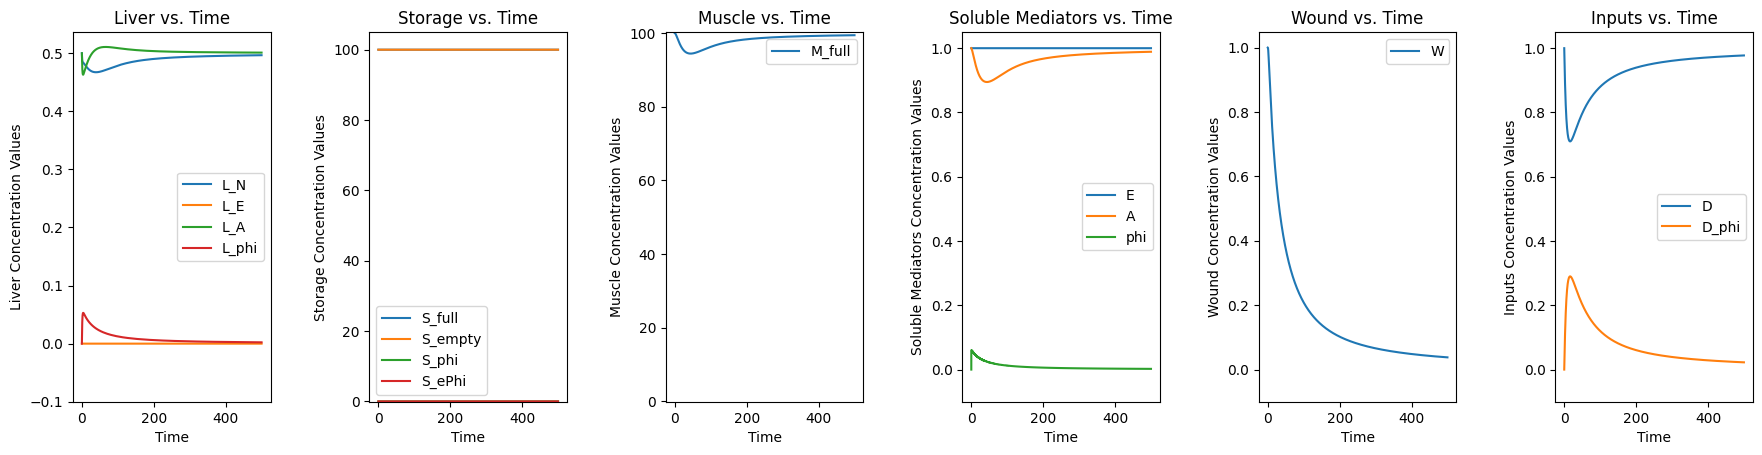

-1.1135405229830078
Final value of W: 0.03783312840662815


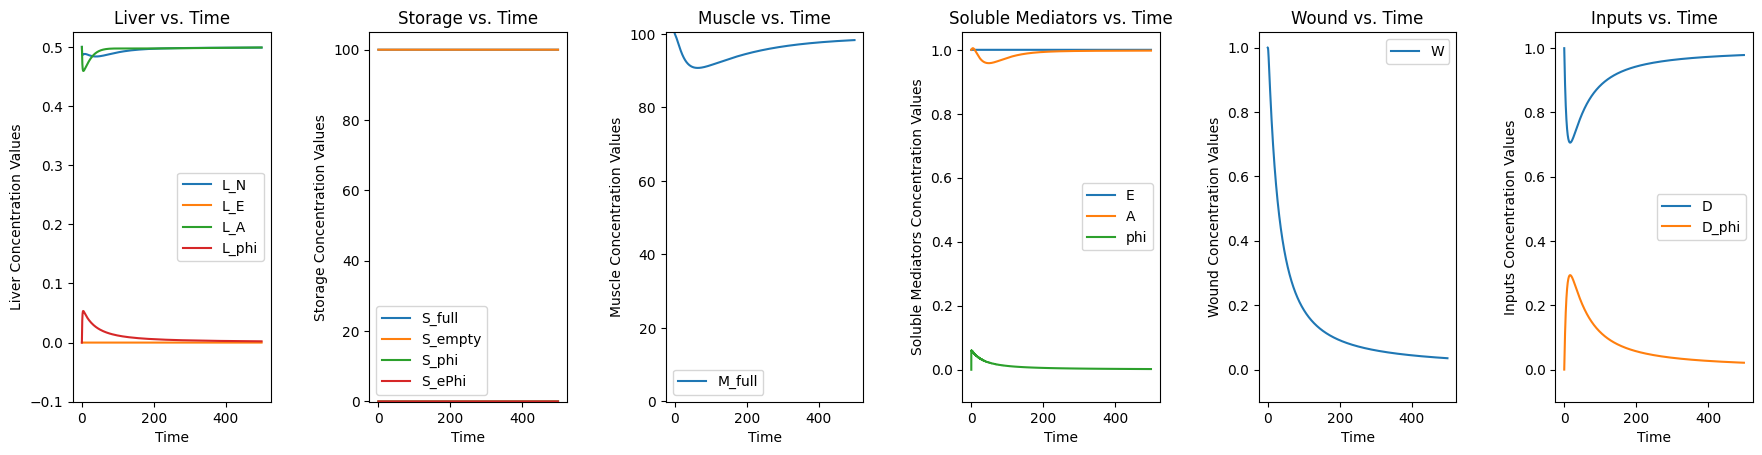

-1.0730819383359838
Final value of W: 0.035136493385480604


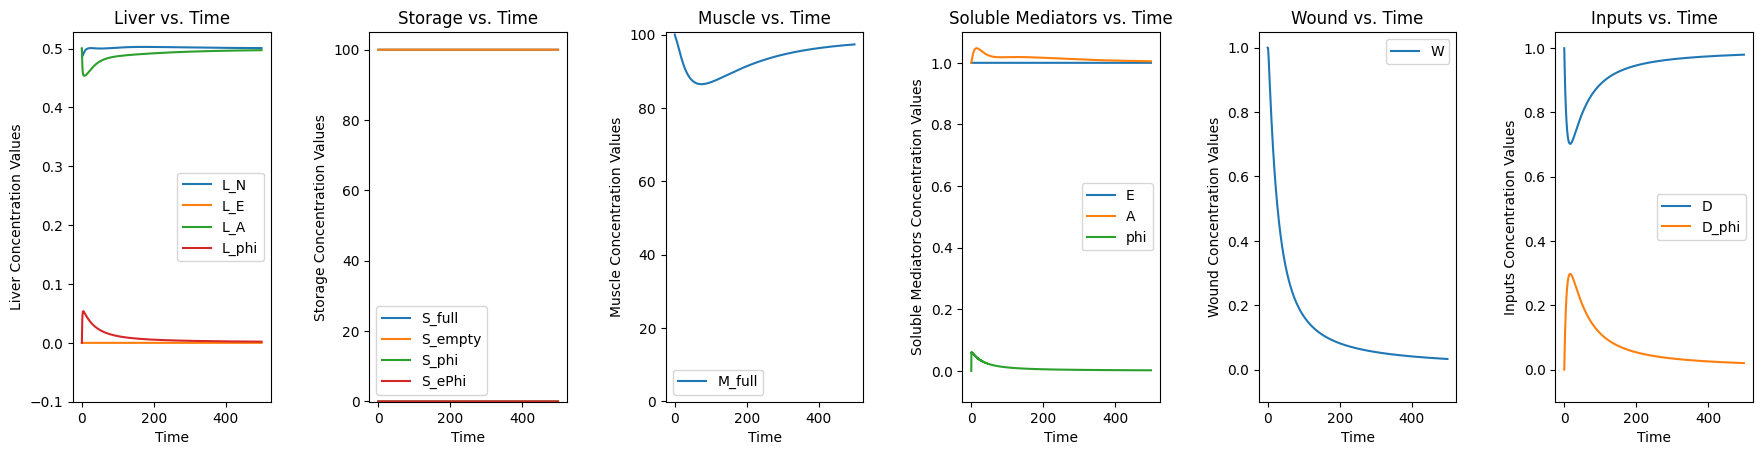

-1.0269810619071702
Final value of W: 0.032803713154316086


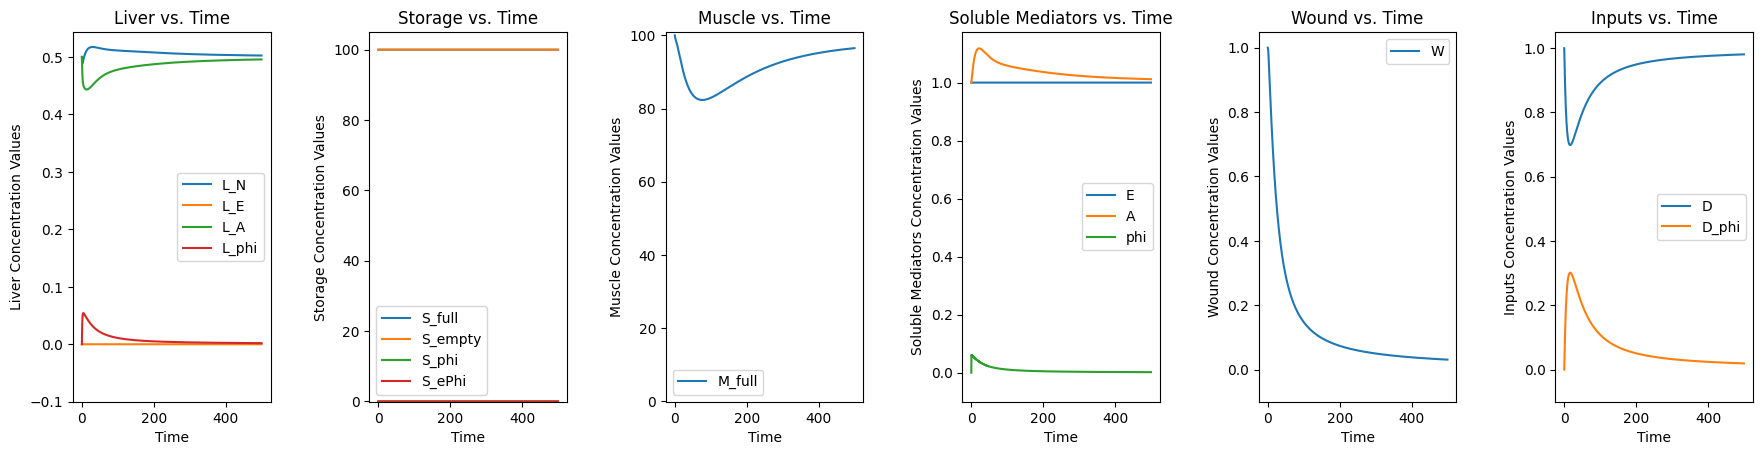

-0.9819978701862244
Final value of W: 0.030775586885285335


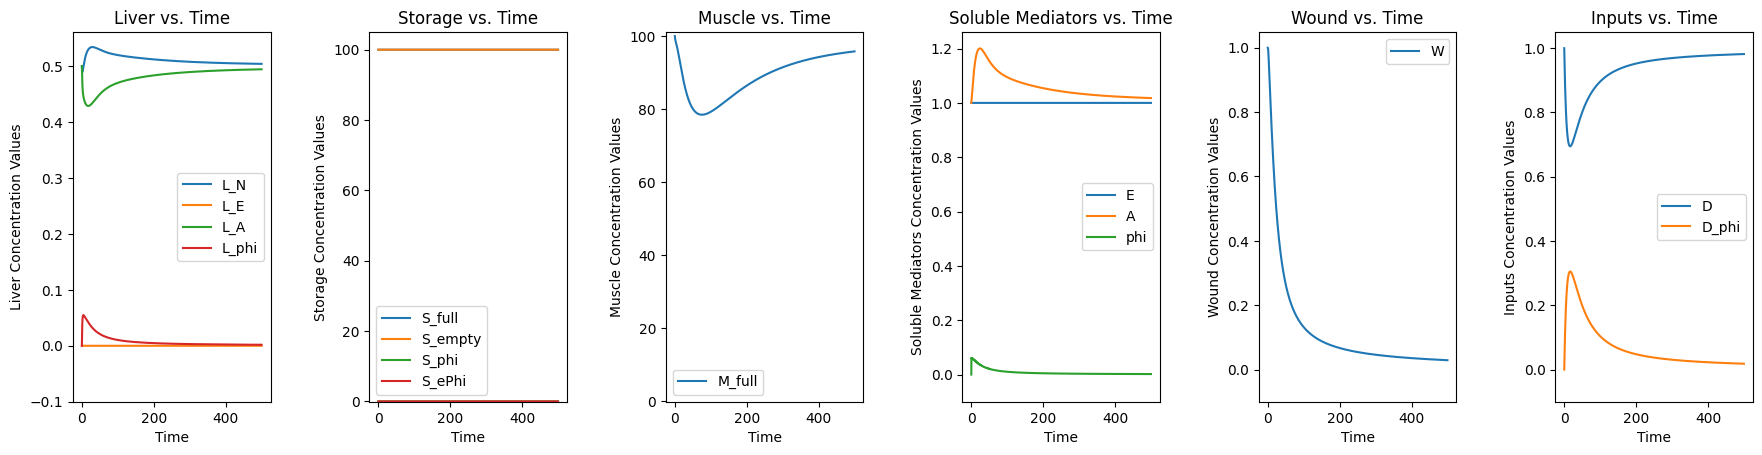

-0.9398761696558134
Final value of W: 0.02900327696996994


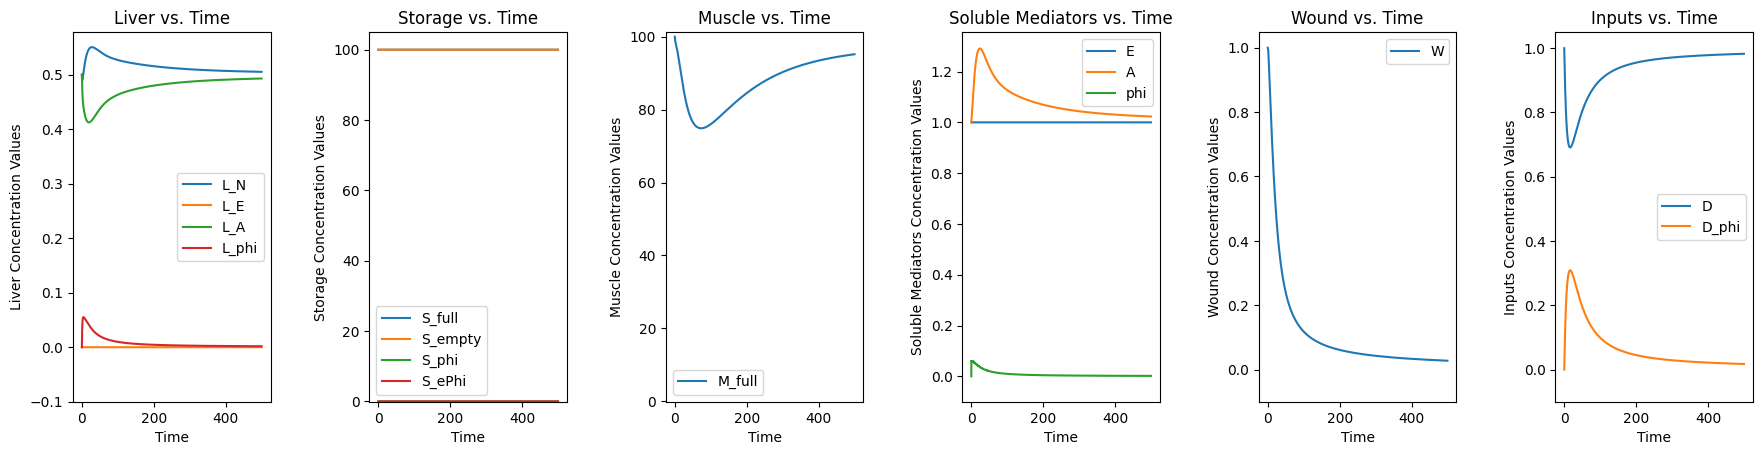

-0.9009337738795906
Final value of W: 0.027446532345903423


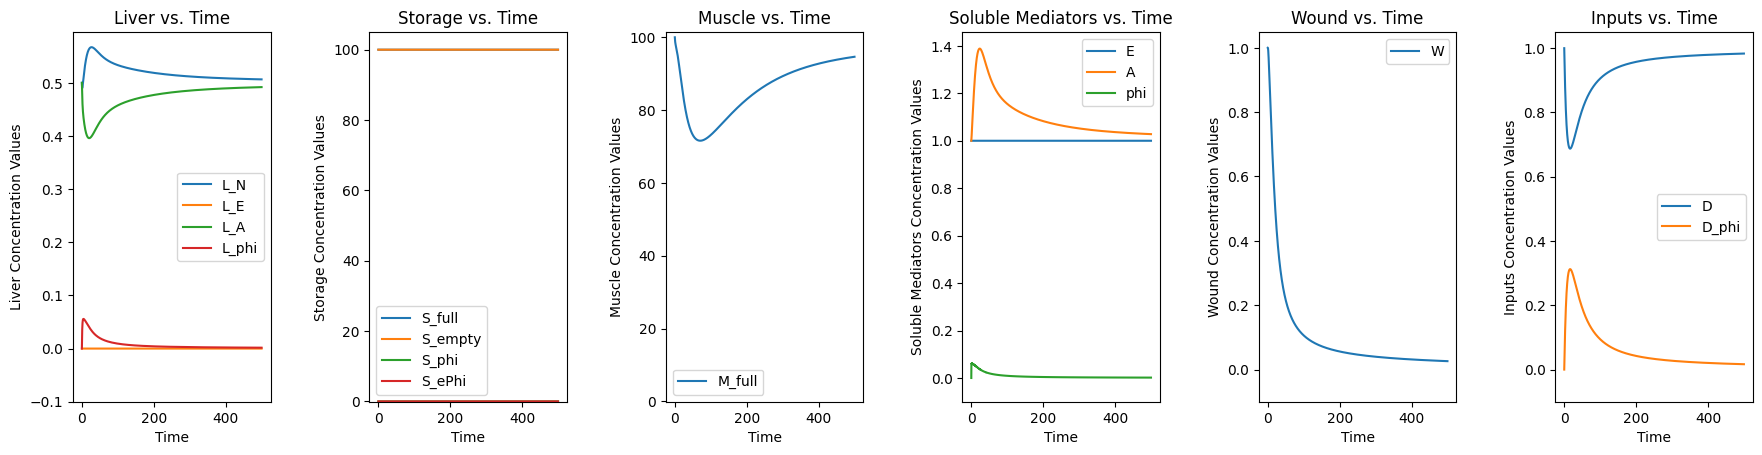

-0.8651406435004203
Final value of W: 0.02607215499678761


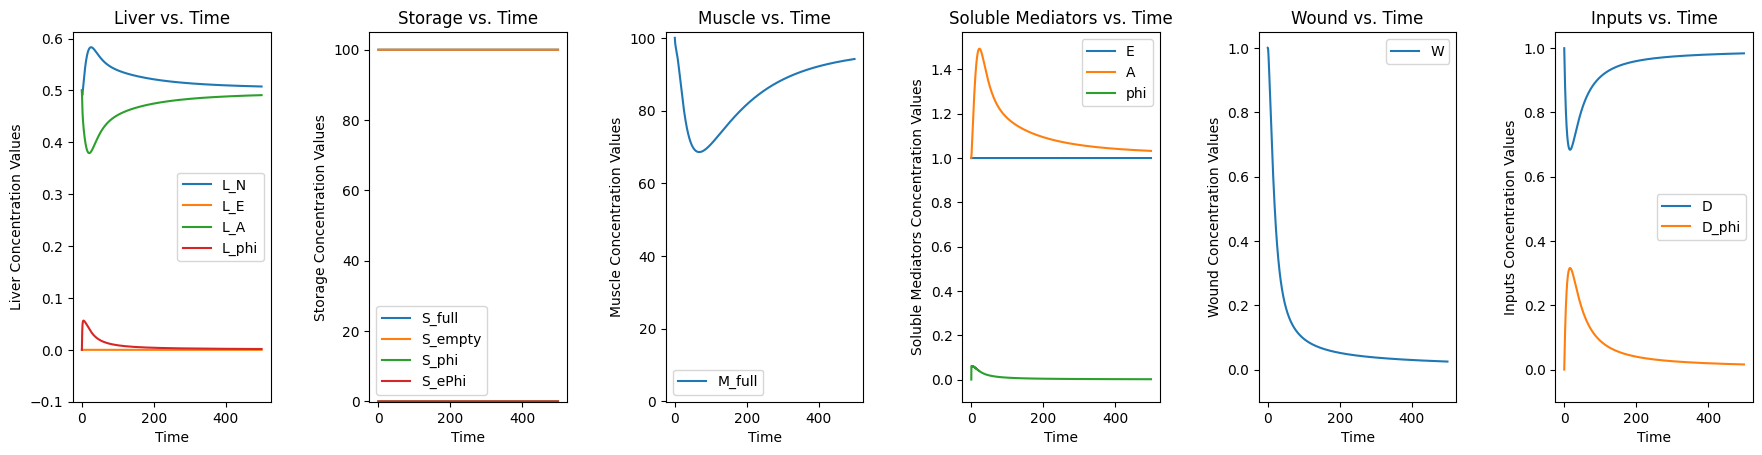

-0.8323541010136613
Final value of W: 0.024852711622692106


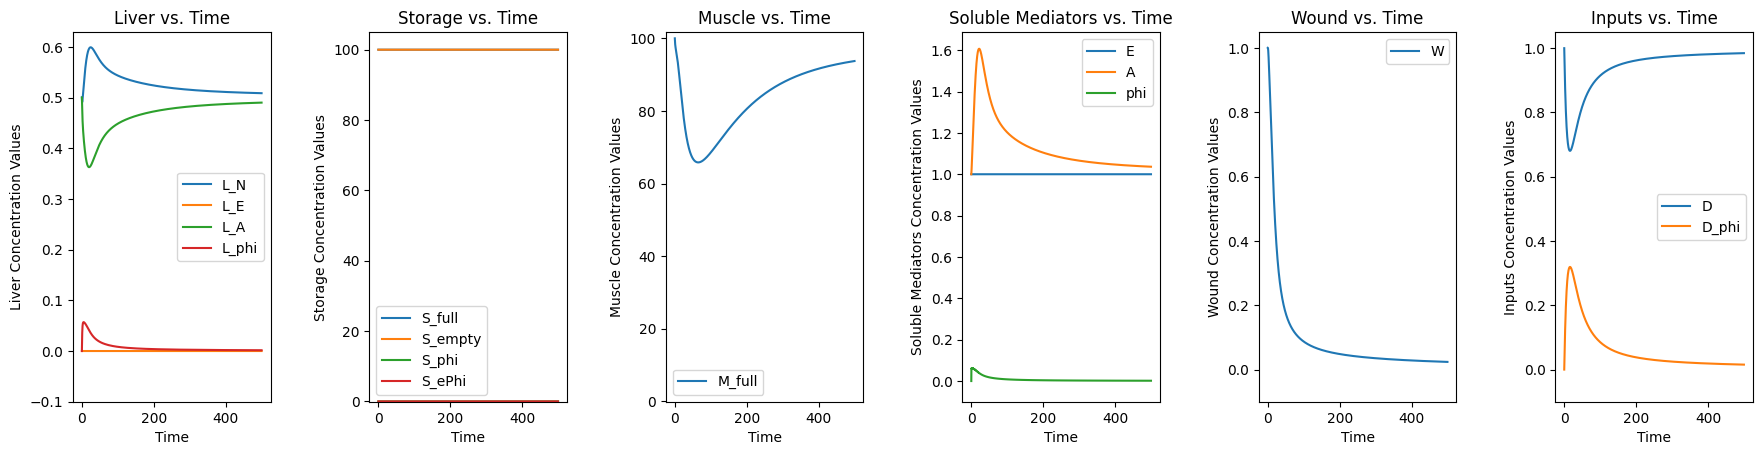

-0.8023880702869828
Final value of W: 0.02376546998229723


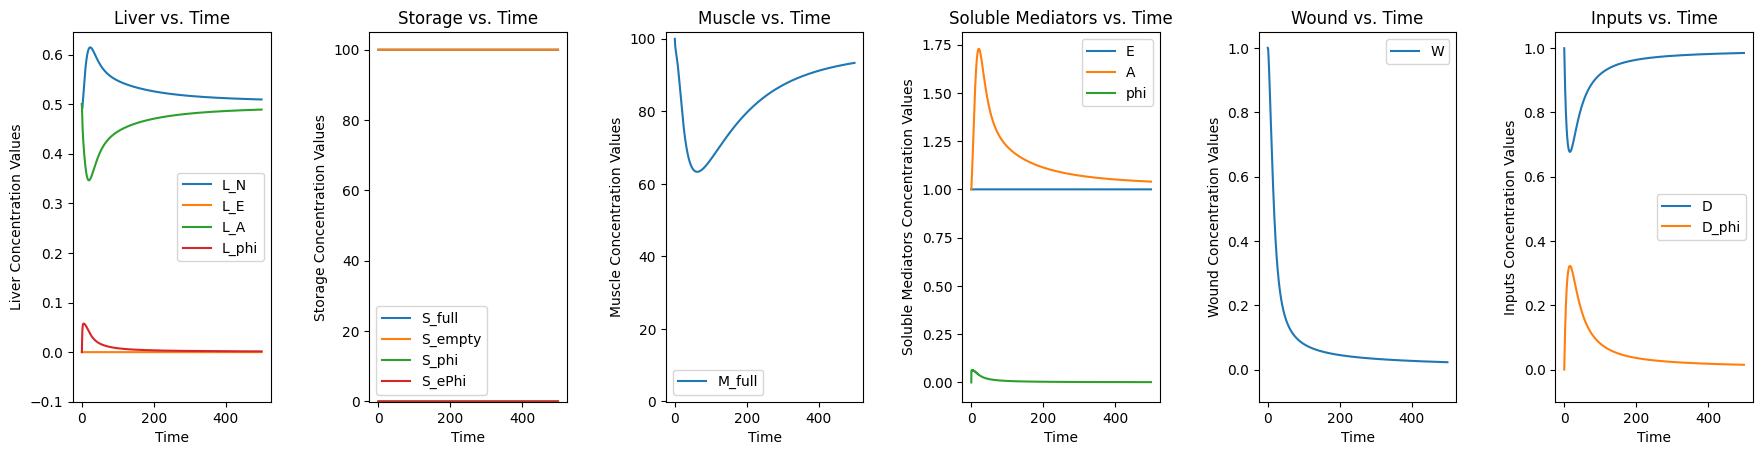

-0.7750402600680988
Final value of W: 0.022791530358989873


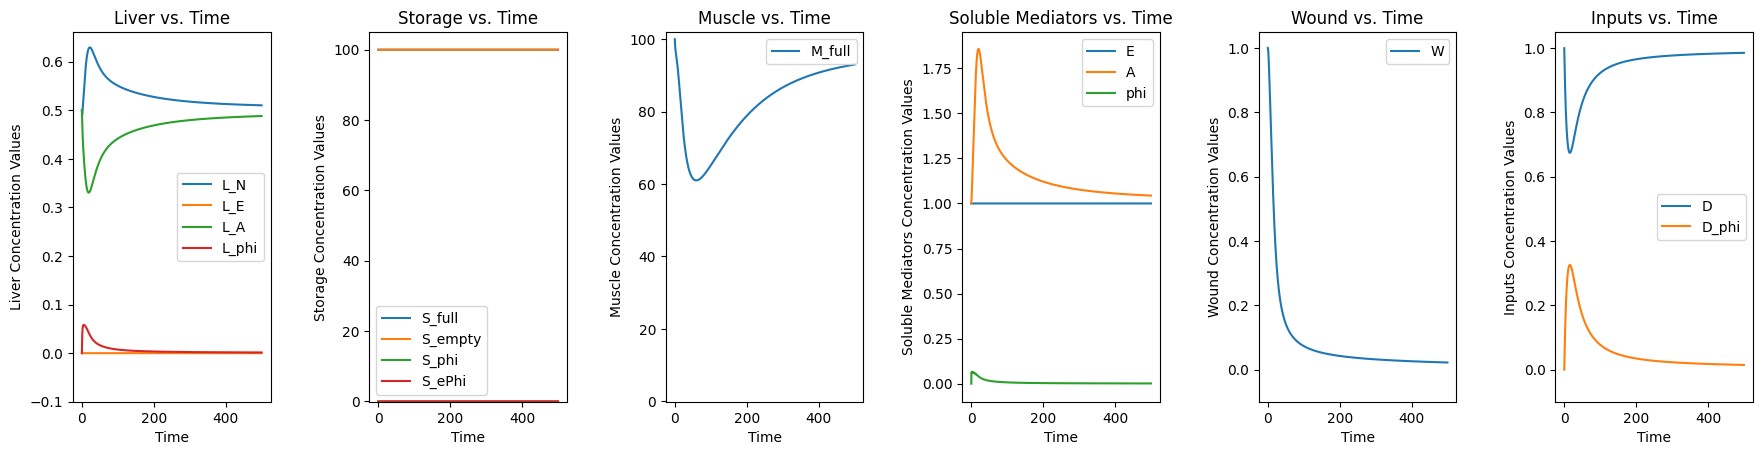

-0.7501053991235134
Final value of W: 0.021915121006650877


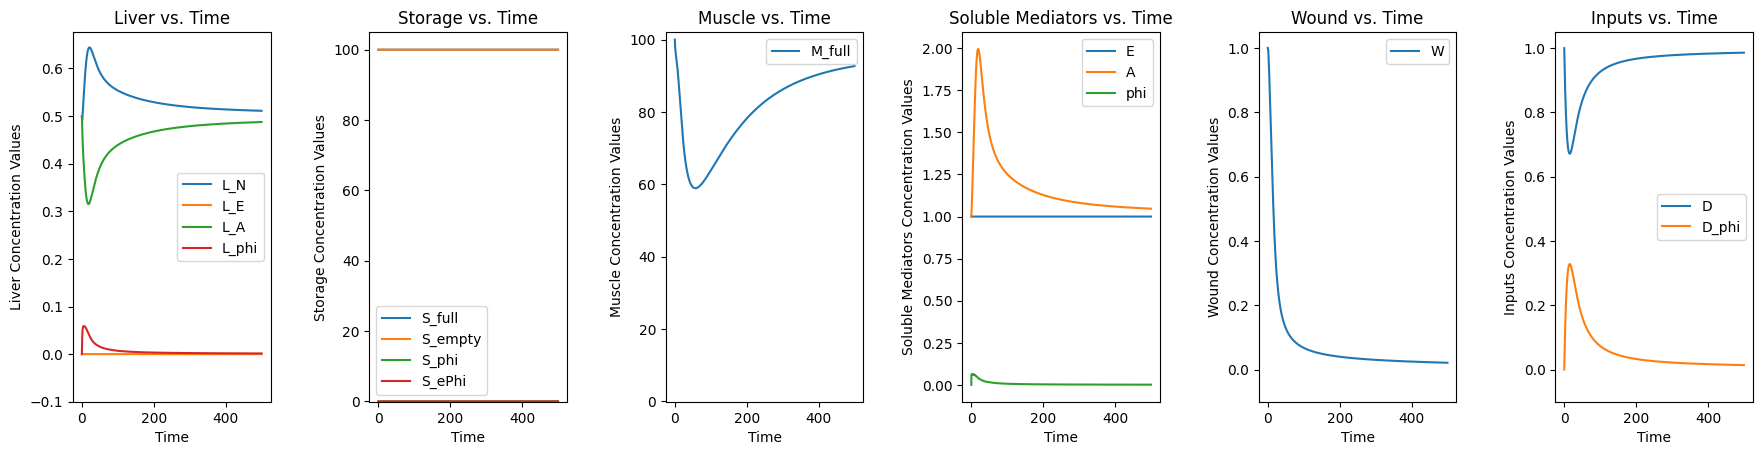

-0.727382431647679
Final value of W: 0.02112302855409395


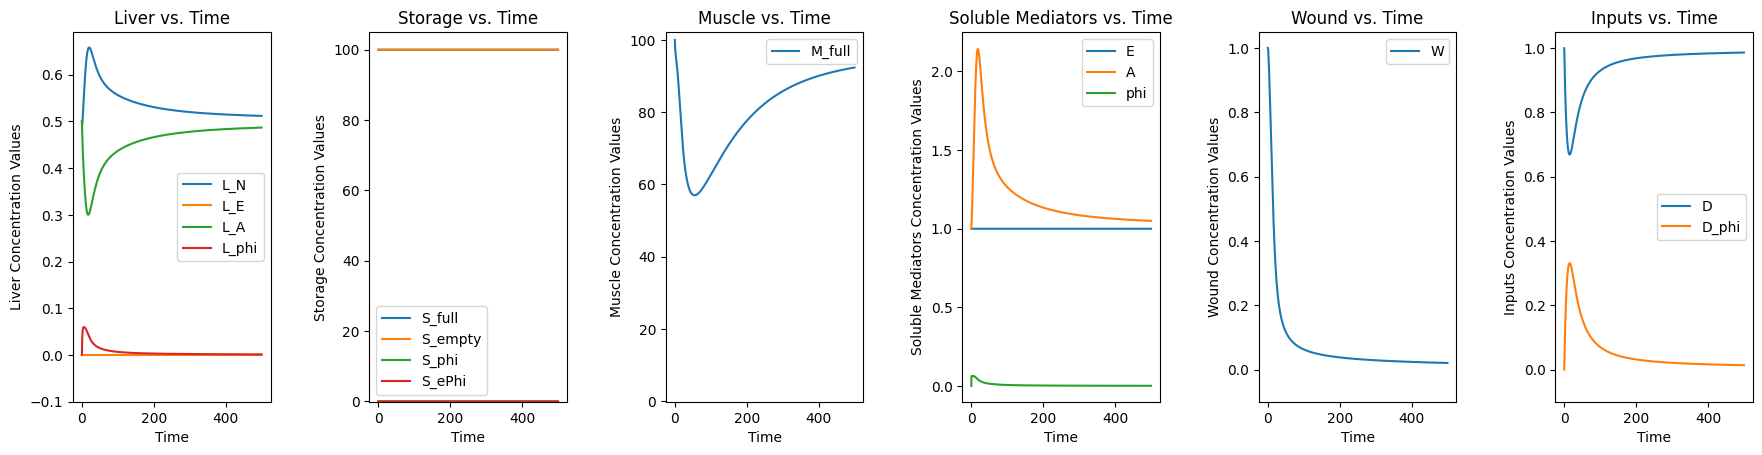

-0.7066793785777573
Final value of W: 0.02040413801113184


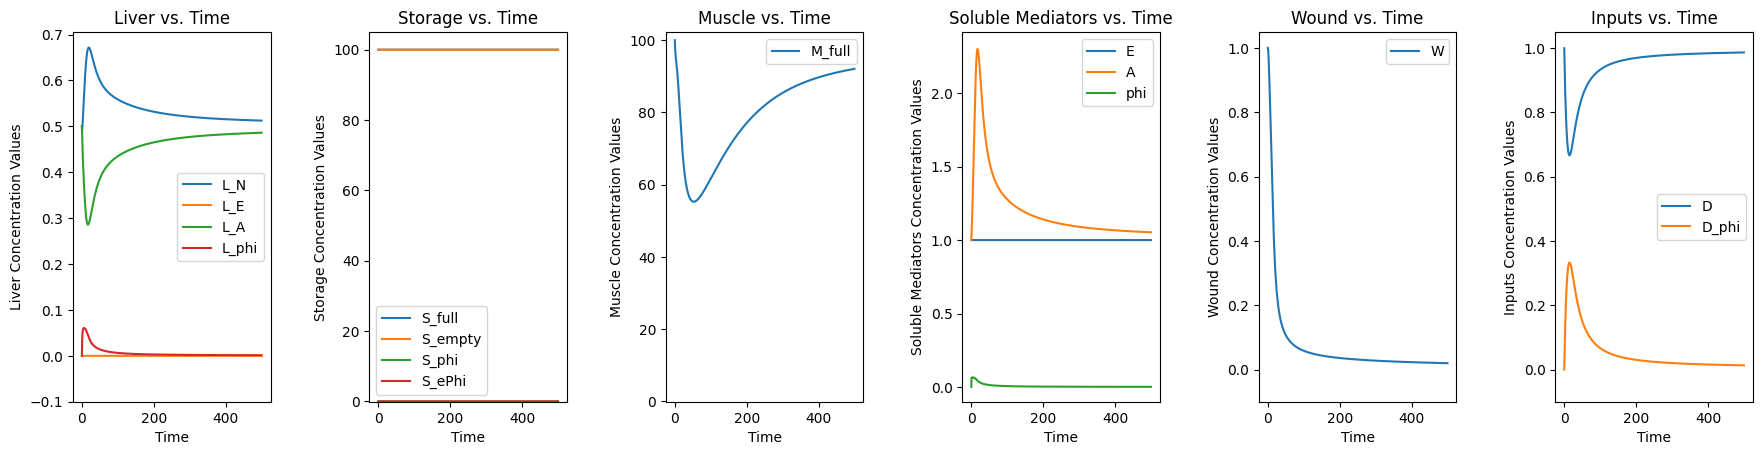

-0.6878154227276048
Final value of W: 0.019749061047839134


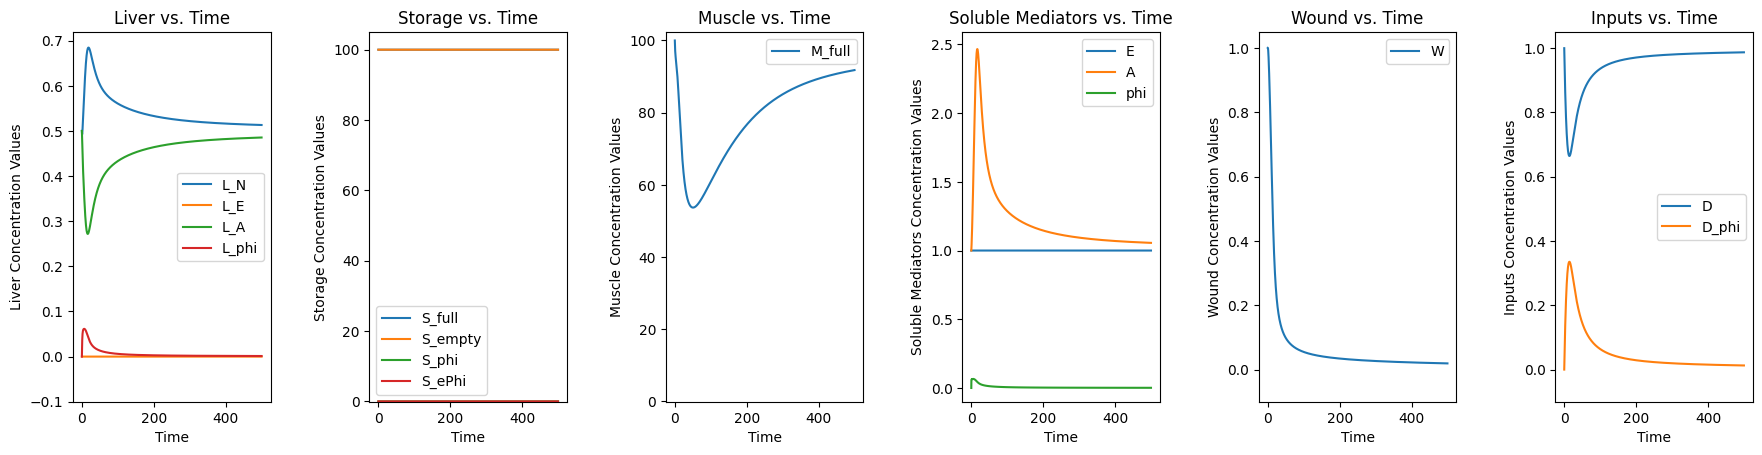

-0.6706232105838469
Final value of W: 0.019149835022357033


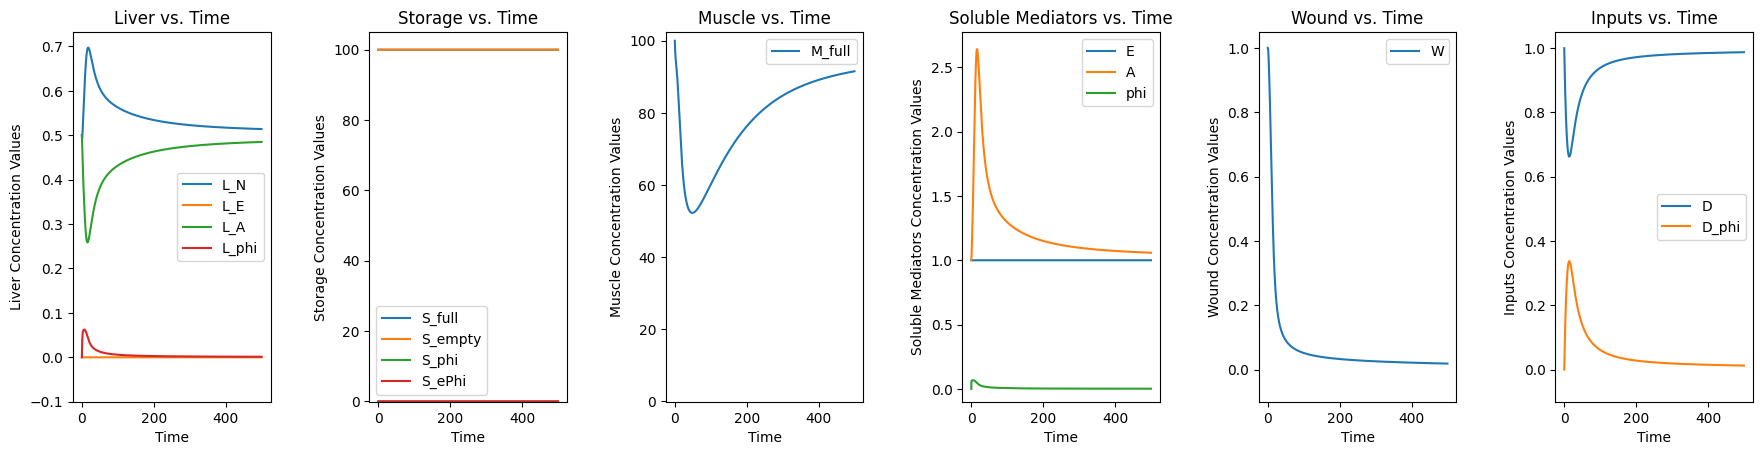

-0.6549483775084408
Final value of W: 0.01859967857716281


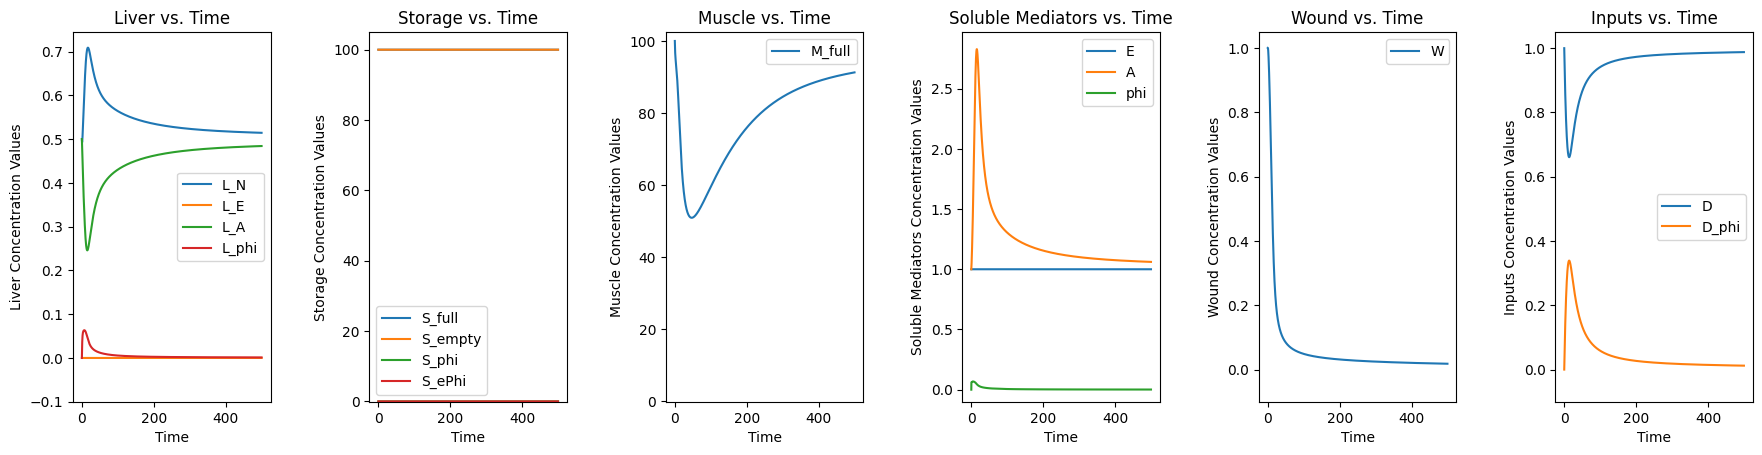

-0.6406501581358635
Final value of W: 0.01809279243397859


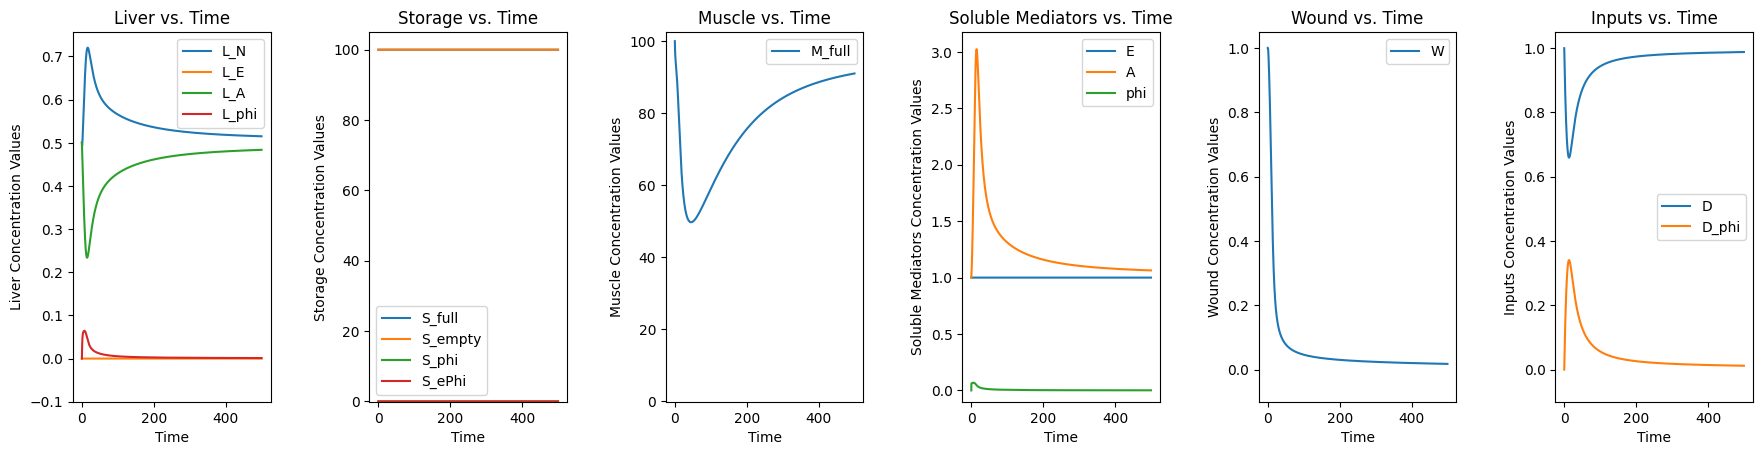

-0.627601343029627
Final value of W: 0.017624196322951004


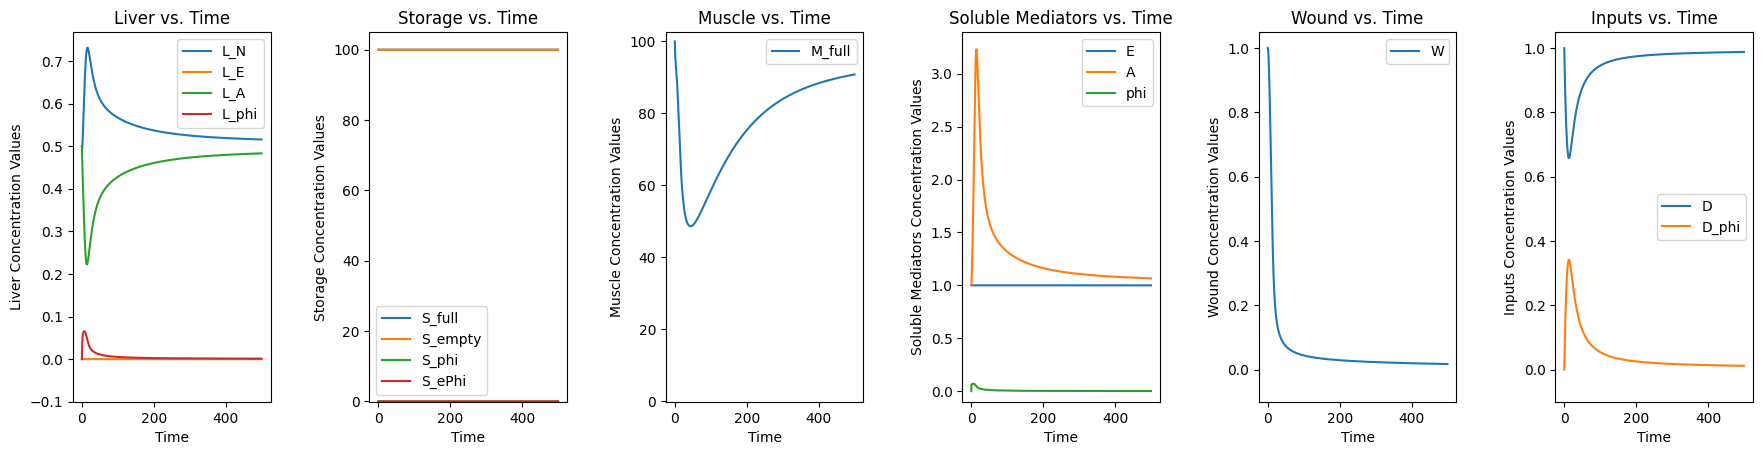

-0.6156863516436144
Final value of W: 0.017189594839441238


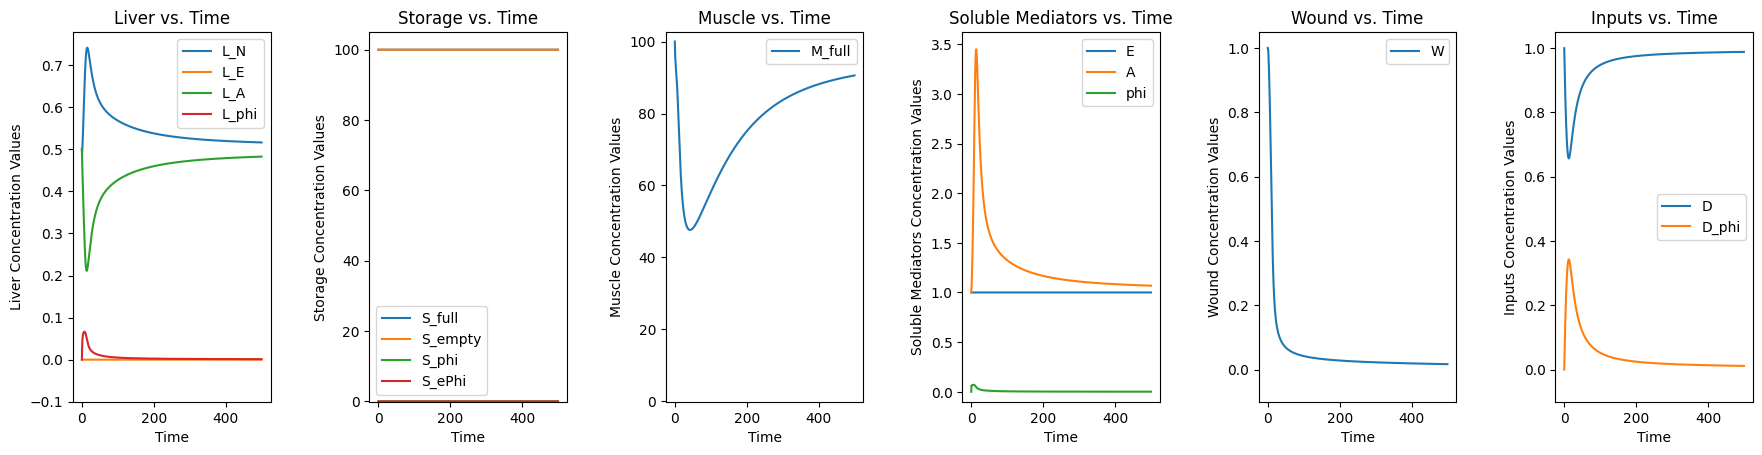

-0.6048023904735293
Final value of W: 0.016785266503893066


In [ ]:
initWound = 1

diet = 1

highwoundValsVsTime = []

highrxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_E', 'L_A', 'L_phi', 'S_full', 'S_empty', 'S_phi', 'S_ePhi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'E', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Storage" : ['S_full', 'S_empty', 'S_phi', 'S_ePhi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['E', 'A', 'phi'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

highrxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

highSimulationOutputs = []

highrxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
highrxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 3: L_A + A -> L_N", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
highrxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
highrxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationParameters["high"], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
highrxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
highrxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
highrxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
highrxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
highrxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
highrxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
highrxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
highrxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
highrxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
#rxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
#rxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
highrxnFlask.addReaction("Reaction 7: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
highrxnFlask.addReaction("Reaction 22: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
highrxnFlask.addReaction("Reaction 8: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
highrxnFlask.addReaction("Reaction 23: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    R = (1 / (numPointsToTest - 1)) * k

    #rxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = R)
    #rxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = 1 - R)


    #This allows S_empty to continue acting as an inflammation sink without changing state
    #rxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = R)
    #rxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = 1 - R)


    #This allows M_full to continue acting as an inflammation sink while not changing state
    highrxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = R)
    highrxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 1 - R)


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    highrxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = R)
    highrxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 1 - R)

    reactionDerivative1 = highrxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    highrxnFlask.runSystem(500)
    
    
    highrxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = highrxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - highrxnFlask.latestSimulationOutput["y"][7] - highrxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {highrxnFlask.getFinalValueOfSpecies('W')}")

    highrxnFlask.resetInitialCondition()

    highSimulationOutputs.append(highrxnFlask.latestSimulationOutput)

In [8]:
#1. Get boolean mask of finalWoundValues, <= 10% of initWound
def calculateWoundHealingTime(timeValues, woundValues, threshold):
  #initWound = woundValues[0], correct?
  healedWound = np.where(woundValues <= threshold * woundValues[0])[0]
  try:
    healedWoundIndex = healedWound[0]
  except(IndexError):
    #This ensures that, if the wound never was healed to the threshold, it
    #automatically reports the longest time
    return timeValues[-1]

  healedWoundTime = timeValues[healedWoundIndex]
  return healedWoundTime


In [9]:
def riemannSum(timeValues, functionValues, side):
  #1. Define summing variable and begin loop
  areaSum = 0
  for k in range(len(timeValues) - 1):
    dt = timeValues[k + 1] - timeValues[k]

    if side == "left":
      height = functionValues[k]
    elif side == "right":
      height = functionValues[k + 1]
    else:
      print("You've made a mistake in entering the side that you would like to approximate the value of the function from. Valid choices are 'left' and 'right'")

    areaSum += height * dt

  return areaSum

In [10]:
def calculateMetricsOnSimulation(simulationOutput):
  timeValues = simulationOutput["t"]
  woundValues = simulationOutput["y"][0]
  fatValues = simulationOutput["y"][7]
  muscleValues = simulationOutput["y"][11]
  aminoAcidLevels = simulationOutput["y"][16]

  startingWeight = 100

  weightDropValues = startingWeight - (muscleValues)
  weightDropValues = weightDropValues / startingWeight

  maxWeightDrop = np.max(weightDropValues)

  #When diet = 1, the steady state value of amino acid level will be 1
  aminoAcidDropValues = 1 - aminoAcidLevels

  maxAminoAcidDrop = np.max(aminoAcidDropValues)

  return (calculateWoundHealingTime(timeValues, woundValues, threshold = 0.1),
          riemannSum(timeValues, weightDropValues, "left"),
          maxWeightDrop,
          riemannSum(timeValues, aminoAcidDropValues, "left"),
          maxAminoAcidDrop)

In [11]:
woundHealingTimeValues = np.zeros((len([20, 40, 60]), numPointsToTest))
weightDropIntegralVals = np.zeros((len([20, 40, 60]), numPointsToTest))
maxWeightDropVals = np.zeros((len([20, 40, 60]), numPointsToTest))
aminoAcidDropIntegralVals = np.zeros((len([20, 40, 60]), numPointsToTest))
maxAminoAcidDropVals = np.zeros((len([20, 40, 60]), numPointsToTest))

for c in range(3):
  for k in range(numPointsToTest):
    simulationOutputObjects = [lowSimulationOutputs, midSimulationOutputs, highSimulationOutputs]
    simulationOutput = simulationOutputObjects[c][k]
    (woundHealingTimeValues[c][k],
      weightDropIntegralVals[c][k],
      maxWeightDropVals[c][k],
      aminoAcidDropIntegralVals[c][k],
      maxAminoAcidDropVals[c][k]) = calculateMetricsOnSimulation(simulationOutput)

print(maxWeightDropVals)

IndexError: index 16 is out of bounds for axis 0 with size 13

32.879750875411375


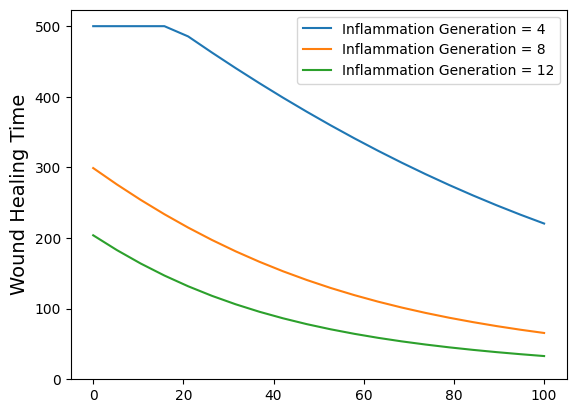

In [ ]:
RsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(RsTested, woundHealingTimeValues[0][:], label = f"Inflammation Generation = {inflammationParameters["low"]}")
plt.plot(RsTested, woundHealingTimeValues[1][:], label = f"Inflammation Generation = {inflammationParameters["mid"]}")
plt.plot(RsTested, woundHealingTimeValues[2][:], label = f"Inflammation Generation = {inflammationParameters["high"]}")

print(woundHealingTimeValues[2][-1])
plt.legend()

plt.ylabel("Wound Healing Time", size = 14)
plt.ylim(bottom = 0)

plt.savefig("FigureImages/Figure3Images/woundHealingTimeVsR.png")

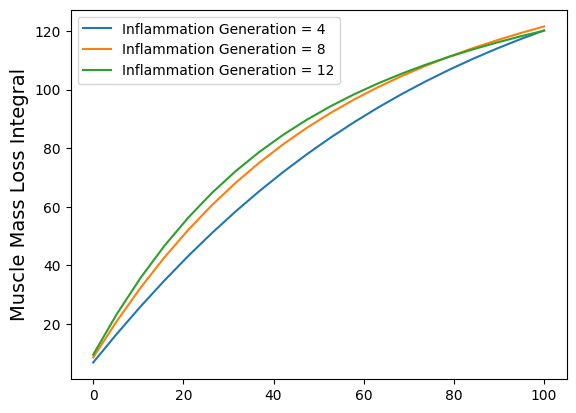

In [ ]:
RsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(RsTested, weightDropIntegralVals[0][:], label = f"Inflammation Generation = {inflammationParameters["low"]}")
plt.plot(RsTested, weightDropIntegralVals[1][:], label = f"Inflammation Generation = {inflammationParameters["mid"]}")
plt.plot(RsTested, weightDropIntegralVals[2][:], label = f"Inflammation Generation = {inflammationParameters["high"]}")

plt.legend()

plt.ylabel("Muscle Mass Loss Integral", size = 14)

plt.savefig("FigureImages/Figure3Images/weightLossVsPercentIMW.png")

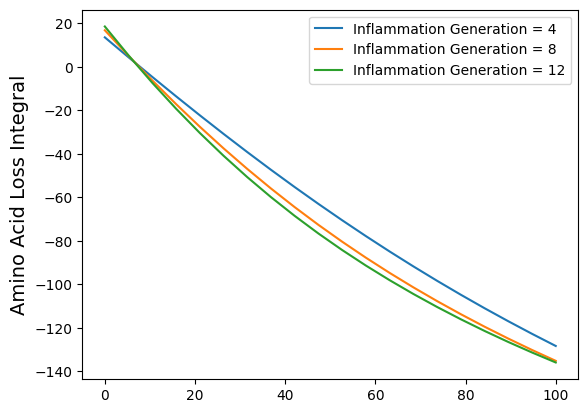

In [ ]:
RsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(RsTested, aminoAcidDropIntegralVals[0][:], label = f"Inflammation Generation = {inflammationParameters["low"]}")
plt.plot(RsTested, aminoAcidDropIntegralVals[1][:], label = f"Inflammation Generation = {inflammationParameters["mid"]}")
plt.plot(RsTested, aminoAcidDropIntegralVals[2][:], label = f"Inflammation Generation = {inflammationParameters["high"]}")

plt.legend()

plt.ylabel("Amino Acid Loss Integral", size = 14)

plt.savefig("FigureImages/Figure3Images/aminoAcidLossVsPercentIMW.png")

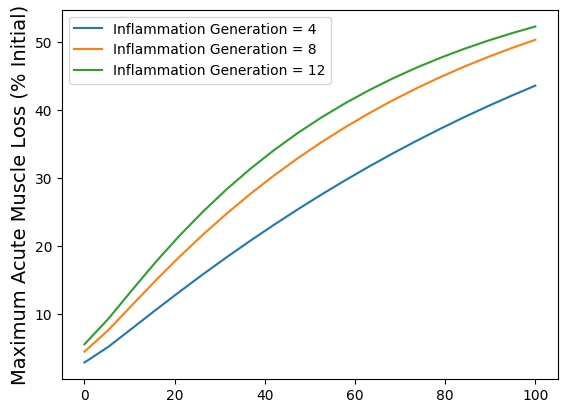

In [ ]:
RsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(RsTested, 100 * maxWeightDropVals[0][:], label = f"Inflammation Generation = {inflammationParameters["low"]}")
plt.plot(RsTested, 100 * maxWeightDropVals[1][:], label = f"Inflammation Generation = {inflammationParameters["mid"]}")
plt.plot(RsTested, 100 * maxWeightDropVals[2][:], label = f"Inflammation Generation = {inflammationParameters["high"]}")

plt.legend()

plt.ylabel("Maximum Acute Muscle Loss (% baseline)", size = 14)

plt.savefig("FigureImages/Figure3Images/maxWeightDropVsPercentIMW.png")